# ECSE 551 – Assignment 1
## Task 1: Data acquisition, cleaning and statistical analysis

In [1]:
# Importing relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes, load_digits

# Plot Formatting
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 100})
sns.set_style("whitegrid")

### 1(a) Load the datasets (Diabetes & Digits)

In [2]:
# Regression dataset: Diabetes
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
df = pd.DataFrame(X, columns=diabetes.feature_names)
df["target"] = y
feats = diabetes.feature_names
print(f"Features: {list(diabetes.feature_names)}")
print("Diabetes shape:", df.shape)
df.head()

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Diabetes shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Classification dataset: Digits
digits = load_digits()
X_dig = digits.data
y_dig = digits.target
df_dig = pd.DataFrame(X_dig, columns=[f"px_{i}" for i in range(64)])
df_dig["target"] = y_dig
print("Digits shape:", df_dig.shape)
df_dig.head()

Digits shape: (1797, 65)


,px_0,px_1,px_2,px_3,px_4,px_5,px_6,px_7,px_8,px_9,...,px_55,px_56,px_57,px_58,px_59,px_60,px_61,px_62,px_63,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


### 1(b) Data cleaning

In [4]:
# Check for missing, infinite and duplicated values on Diabetes Dataset
print("Diabetes Dataset")
print("Number of missing values:", df.isna().sum().sum())
print("Number of infinite values:", np.isinf(df.select_dtypes("number")).sum().sum())
print("Number of duplicated rows:", df.duplicated().sum())

# Erroneous-value checks
print("Diabetes target range:", y.min(), "to", y.max())

Diabetes Dataset
Number of missing values: 0
Number of infinite values: 0
Number of duplicated rows: 0
Diabetes target range: 25.0 to 346.0


In [5]:
# Check for missing, infinite and duplicated values on Digits Dataset
print("Digits Dataset")
print("Number of missing values:", df_dig.isna().sum().sum())
print("Number of infinite values:", np.isinf(df_dig.select_dtypes("number")).sum().sum())
print("Number of duplicated rows:", df_dig.duplicated().sum())

# Erroneous-value checks
print("Digits pixel range:", X_dig.min(), "to", X_dig.max())
print("All integers:", np.all(X_dig == X_dig.astype(int)))
print("Digits labels:", np.unique(y_dig))

Digits Dataset
Number of missing values: 0
Number of infinite values: 0
Number of duplicated rows: 0
Digits pixel range: 0.0 to 16.0
All integers: True
Digits labels: [0 1 2 3 4 5 6 7 8 9]


No missing, infinite or duplicated values, and all values are in valid ranges, so no cleaning is needed.

### 1(c) Statistical analysis: Diabetes

In [6]:
# basic stats + skew/kurtosis for each column
summary = df.describe().T[["mean", "std", "min", "max"]]
summary["skew"] = df.skew()          # skew > 0 means a longer right tail
summary["excess_kurt"] = df.kurt()   # 0 for a Gaussian, > 0 means heavier tails
summary["n_unique"] = df.nunique()   # few unique values = discrete feature
summary.round(4)

,mean,std,min,max,skew,excess_kurt,n_unique
age,-0.0000,0.0476,-0.1072,0.1107,-0.2314,-0.6712,58
sex,0.0000,0.0476,-0.0446,0.0507,0.1274,-1.9928,2
bmi,-0.0000,0.0476,-0.0903,0.1706,0.5981,0.0951,163
bp,-0.0000,0.0476,-0.1124,0.1320,0.2907,-0.5328,100
s1,-0.0000,0.0476,-0.1268,0.1539,0.3781,0.2329,141
s2,0.0000,0.0476,-0.1156,0.1988,0.4366,0.6014,302
s3,-0.0000,0.0476,-0.1023,0.1812,0.7993,0.9815,63
s4,-0.0000,0.0476,-0.0764,0.1852,0.7354,0.4444,66
s5,0.0000,0.0476,-0.1261,0.1336,0.2918,-0.1344,184
s6,0.0000,0.0476,-0.1378,0.1356,0.2079,0.2369,56


In [7]:
# sklearn already centres and scales the features (mean 0, sum of squares 1), so std should be 1/sqrt(n)
print("1/sqrt(n) =", round(1 / np.sqrt(len(df)), 4))
print("Sum of squares per feature:", (df[feats] ** 2).sum().round(3).values)

# original units, to see the real ranges
raw = load_diabetes(scaled=False)
pd.DataFrame(raw.data, columns=raw.feature_names).describe().T[["mean", "min", "max"]].round(2)

1/sqrt(n) = 0.0476
Sum of squares per feature: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,mean,min,max
age,48.52,19.00,79.00
sex,1.47,1.00,2.00
bmi,26.38,18.00,42.20
bp,94.65,62.00,133.00
s1,189.14,97.00,301.00
s2,115.44,41.60,242.40
s3,49.79,22.00,99.00
s4,4.07,2.00,9.09
s5,4.64,3.26,6.11
s6,91.26,58.00,124.00


Features are already centred and scaled by sklearn (mean 0, std ≈ 0.048), so no extra scaling is needed. The target is unscaled (25–346).

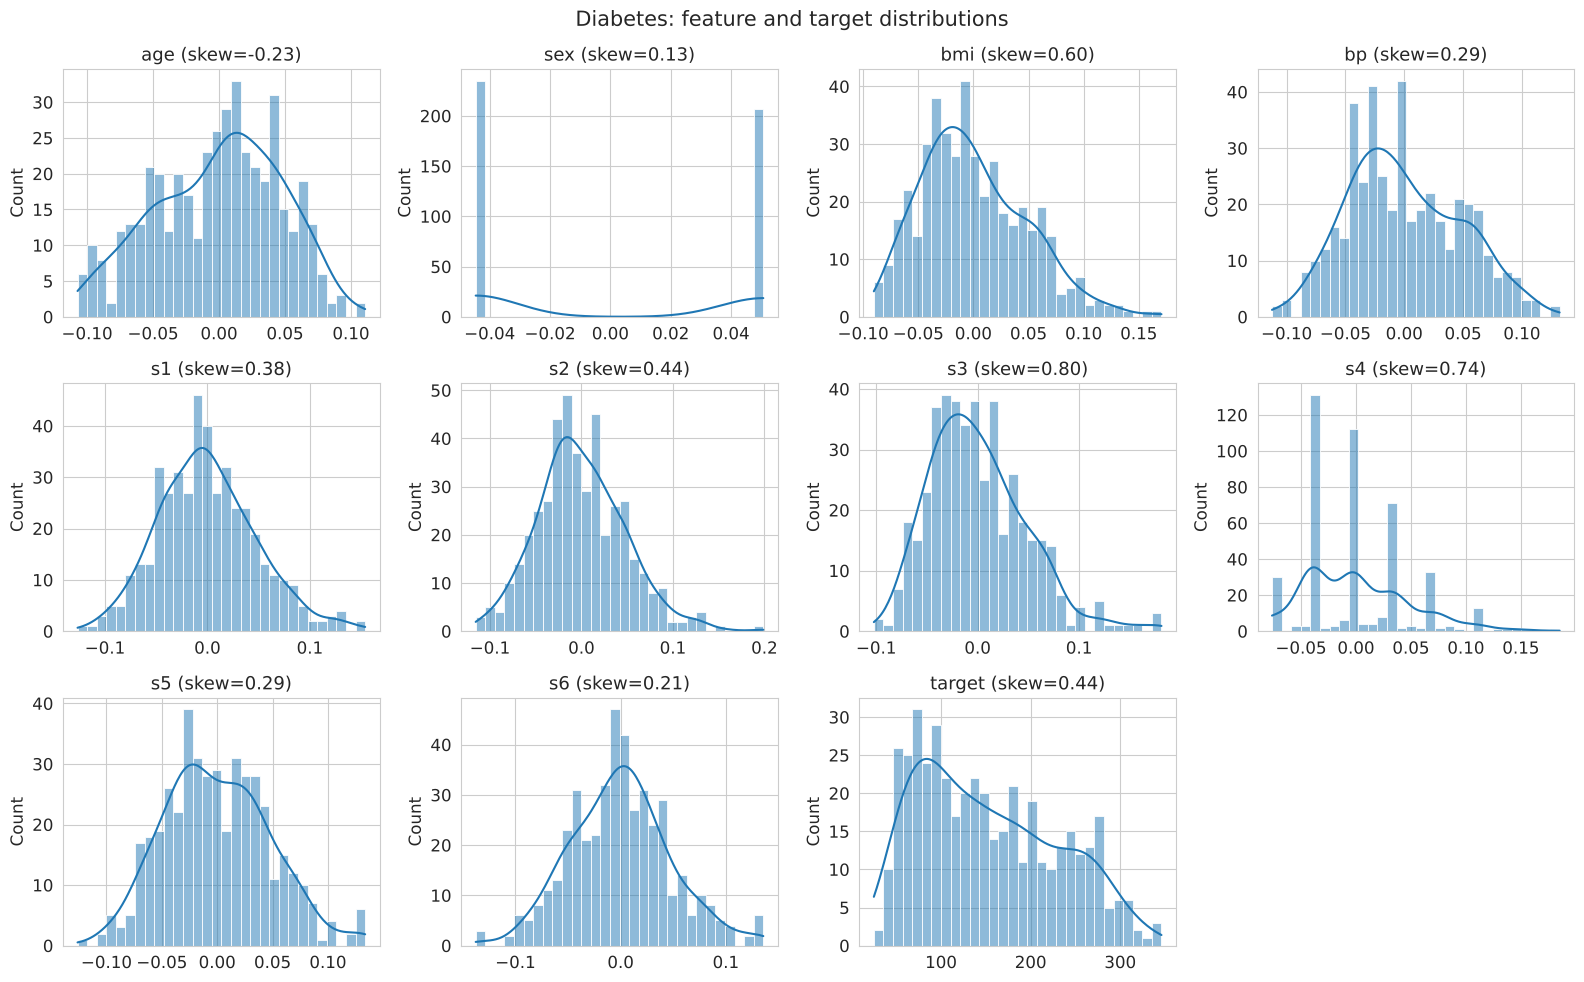

In [8]:
# histograms of every column
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, bins=30)  # kde = smooth density curve
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Diabetes: feature and target distributions", fontsize=15)
plt.tight_layout()
plt.show()

All features are unimodal except sex (binary). bmi, s3 and s4 are right-skewed, no feature has heavy tails, and sex and s4 are discrete.

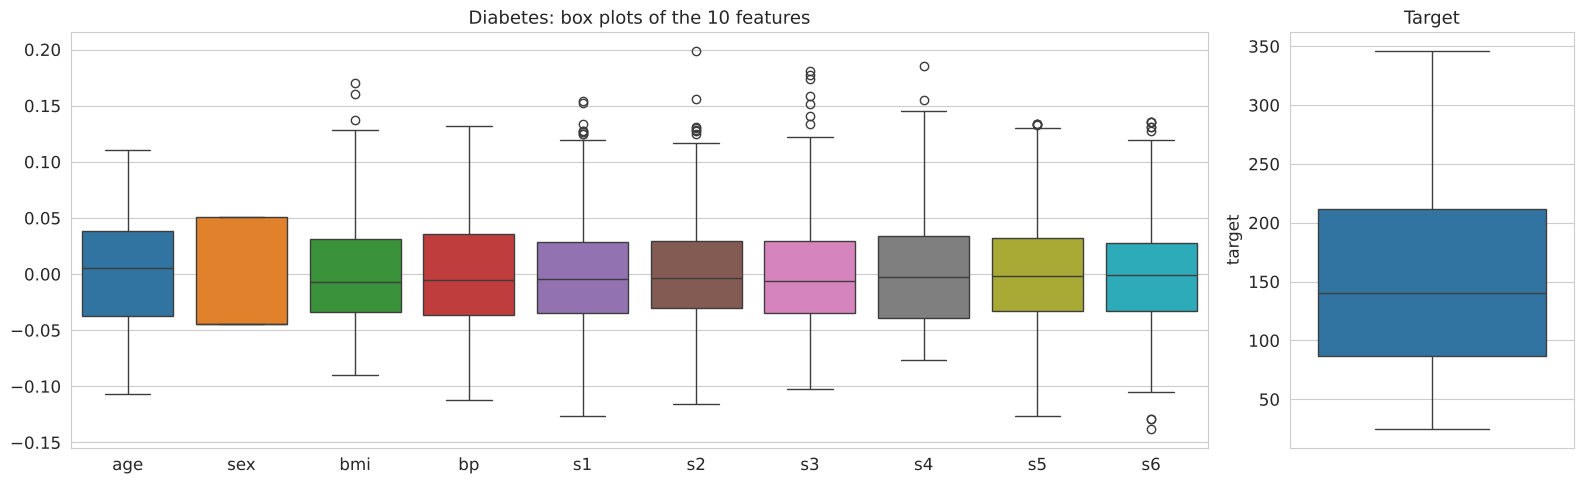

In [9]:
# Box plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [4, 1]})
sns.boxplot(data=df[feats], ax=axes[0])
axes[0].set_title("Diabetes: box plots of the 10 features")
sns.boxplot(y=df["target"], ax=axes[1])
axes[1].set_title("Target")
plt.tight_layout()
plt.show()

There are few outliers, and they are plausible patient values, so we keep them.

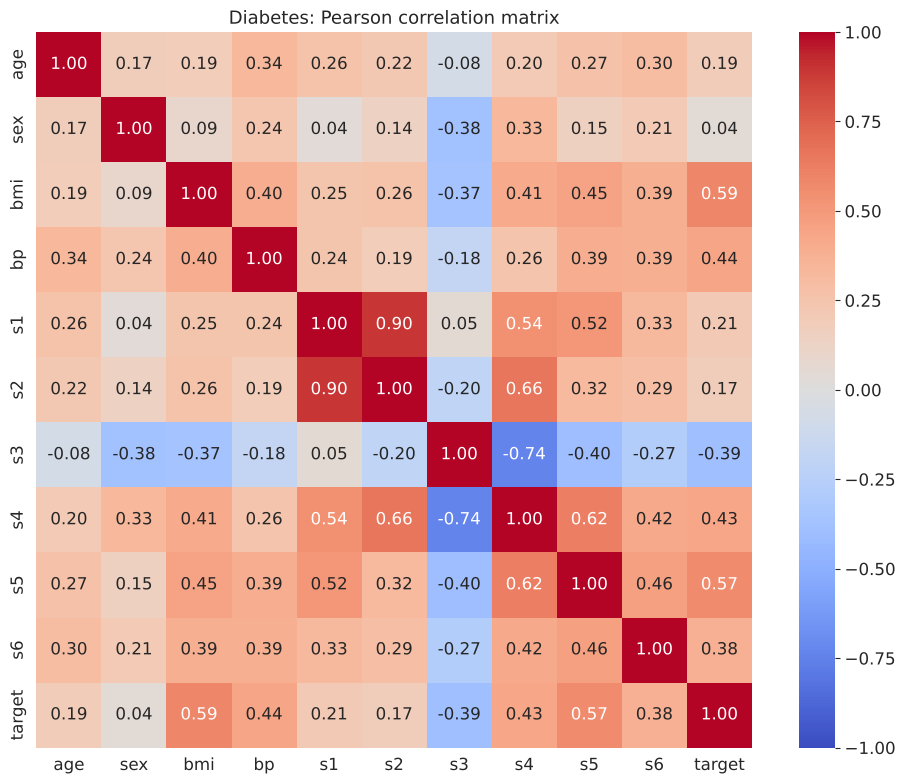

Correlation with target (sorted):
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s3    -0.395
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
Name: target, dtype: float64


In [10]:
# Pearson Correlation Matrix + HeatMap
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Diabetes: Pearson correlation matrix")
plt.tight_layout()
plt.show()

print("Correlation with target (sorted):")
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(3))

Strongest correlations with the target: bmi (0.59) and s5 (0.57). The collinear pairs s1–s2 (0.90) and s3–s4 (−0.74) motivate regularisation.

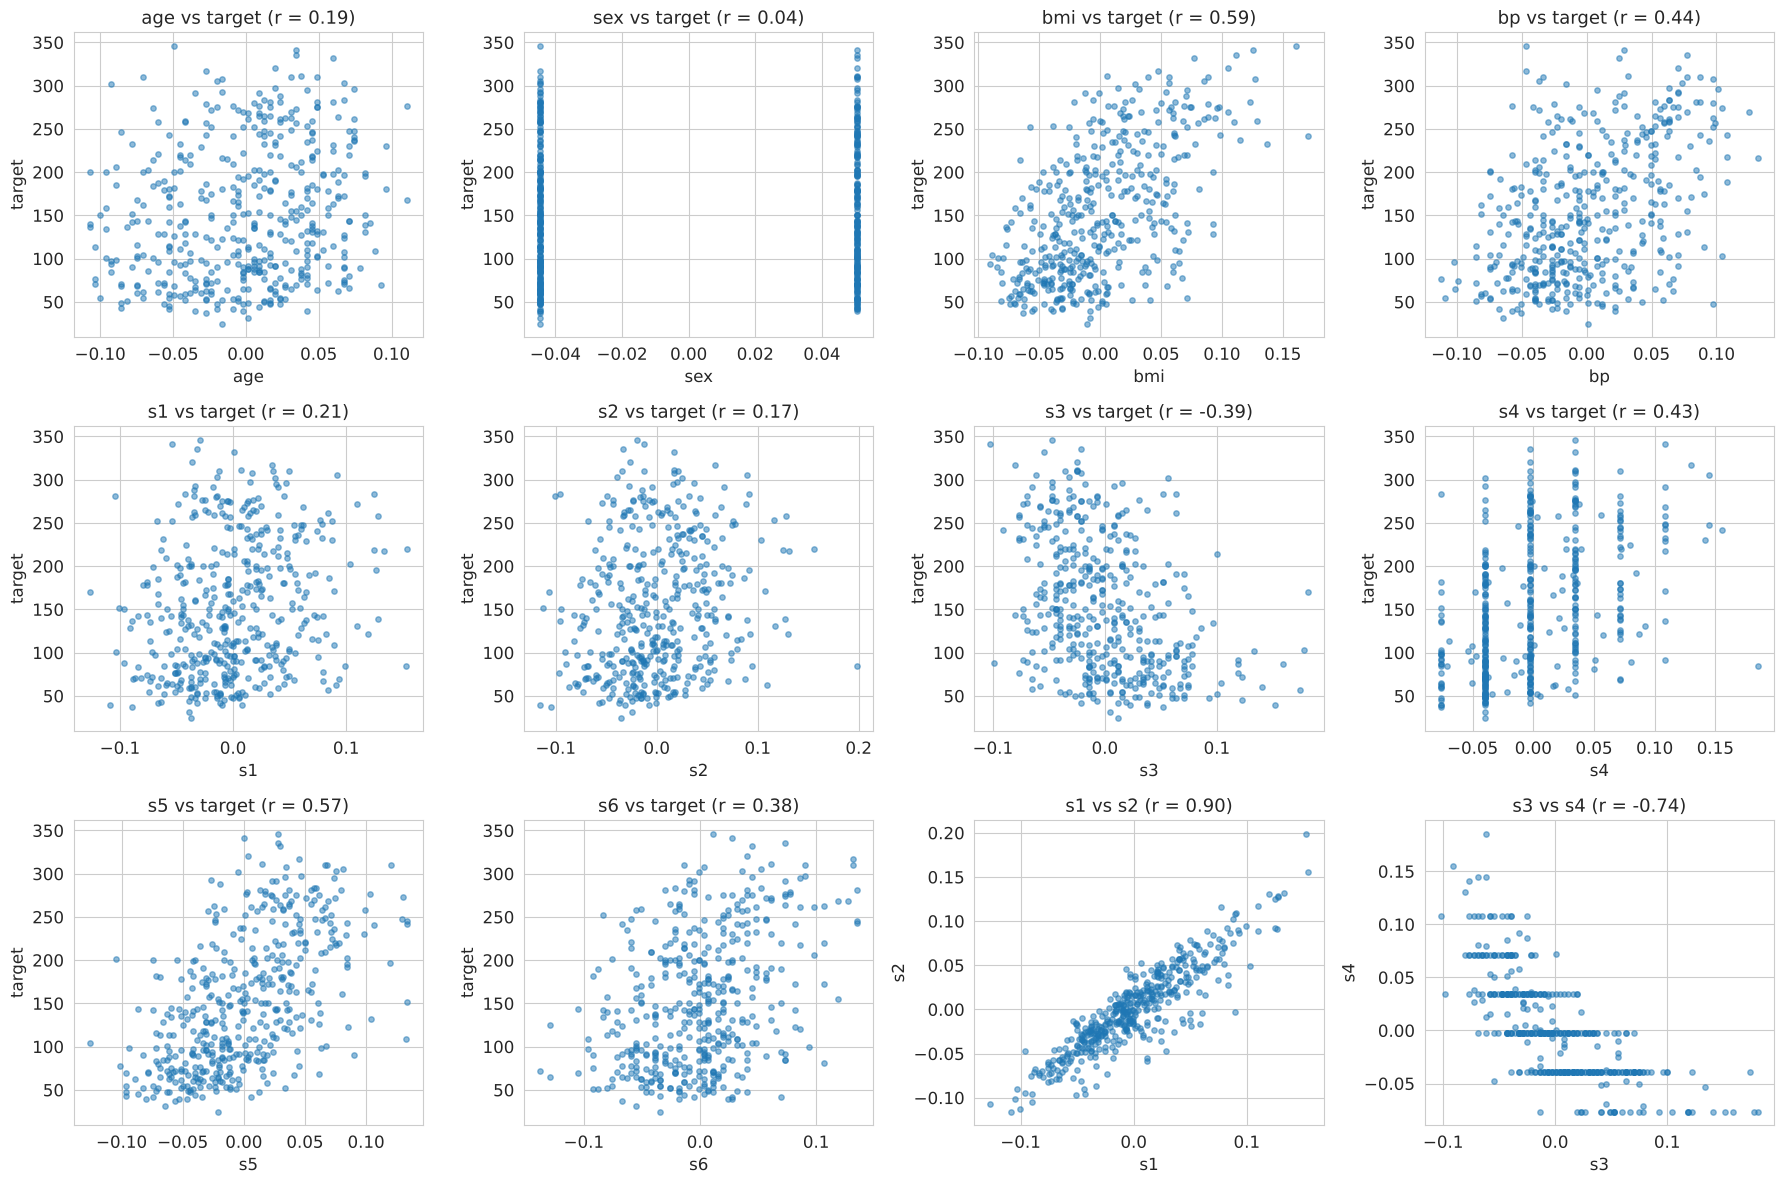

In [11]:
# Scatter Plots
# each feature vs target, plus the two collinear pairs we found
pairs = [(f, "target") for f in feats] + [("s1", "s2"), ("s3", "s4")]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, (fx, fy) in zip(axes.flat, pairs):
    ax.scatter(df[fx], df[fy], alpha=0.5, s=15)
    ax.set_title(f"{fx} vs {fy} (r = {corr.loc[fx, fy]:.2f})")
    ax.set_xlabel(fx)
    ax.set_ylabel(fy)
plt.tight_layout()
plt.show()

The relationships with the target are roughly linear but noisy, and s1 vs s2 is almost a straight line.

### 1(c) Statistical analysis: Digits

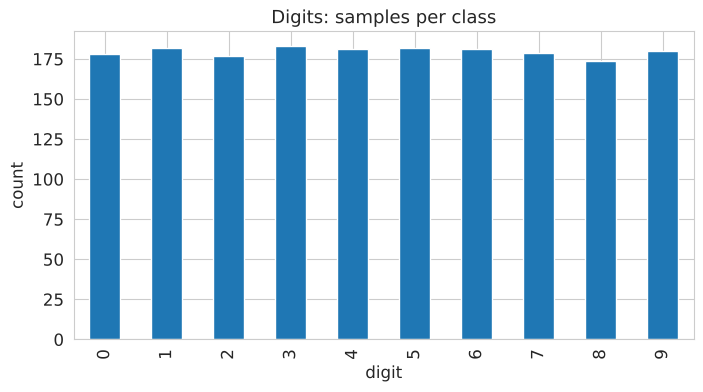

{0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


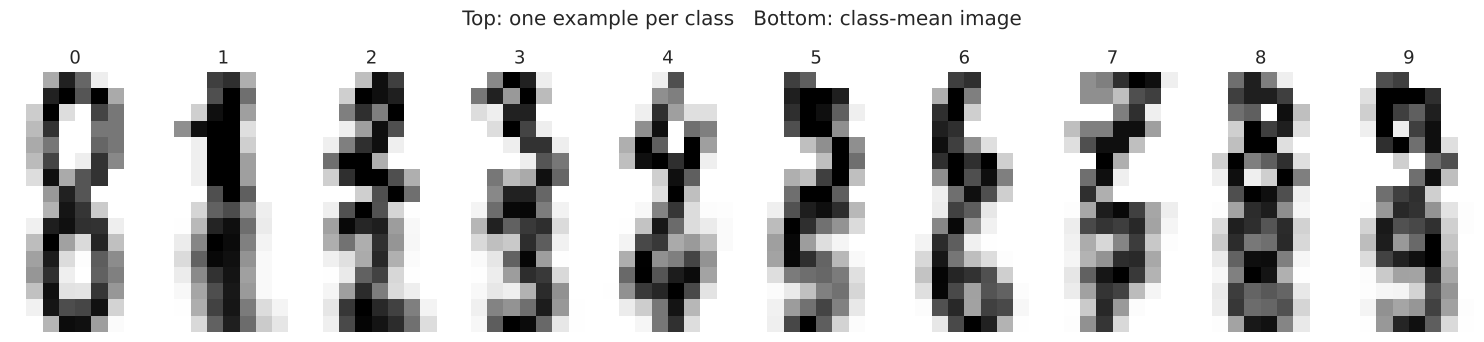

In [12]:
# number of samples per digit
counts = pd.Series(y_dig).value_counts().sort_index()
plt.figure(figsize=(8, 4))
counts.plot(kind="bar")
plt.title("Digits: samples per class")
plt.xlabel("digit"); plt.ylabel("count")
plt.show()
print(counts.to_dict())

# one example and the average image for each digit
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for d in range(10):
    axes[0, d].imshow(X_dig[y_dig == d][0].reshape(8, 8), cmap="gray_r")
    axes[0, d].set_title(str(d)); axes[0, d].axis("off")
    axes[1, d].imshow(X_dig[y_dig == d].mean(0).reshape(8, 8), cmap="gray_r")
    axes[1, d].axis("off")
fig.suptitle("Top: one example per class   Bottom: class-mean image")
plt.tight_layout()
plt.show()

Classes are balanced (≈ 10% each), so accuracy is a fair metric.

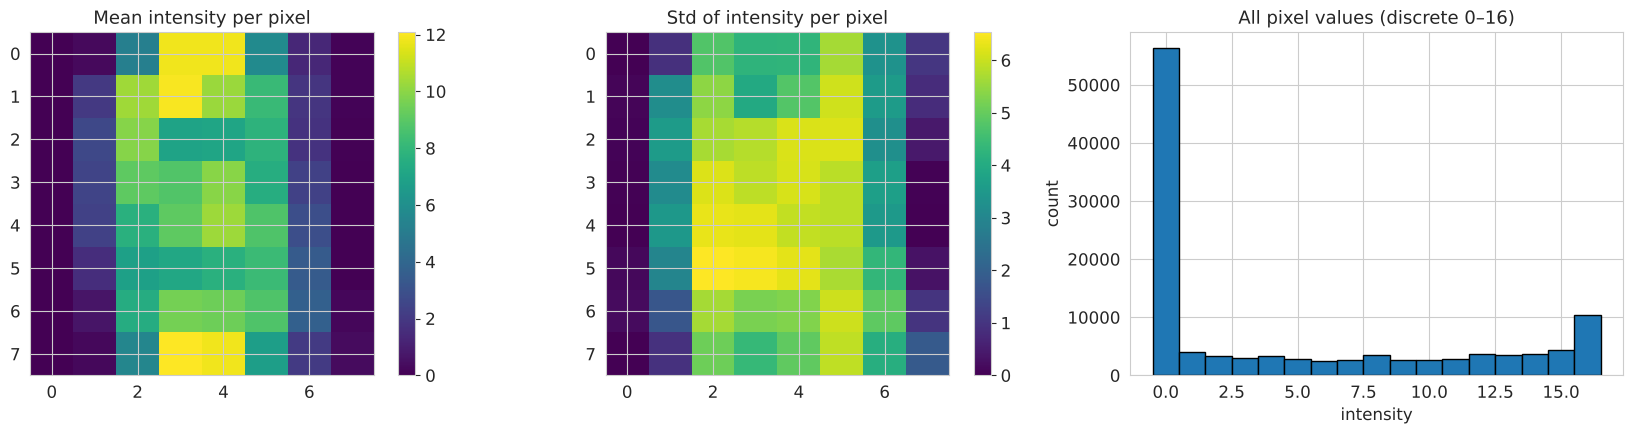

Fraction of pixel values equal to 0: 0.489


In [13]:
# Pixel statistics (2 heatmaps + 1 histogram)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
im = axes[0].imshow(X_dig.mean(0).reshape(8, 8), cmap="viridis")
axes[0].set_title("Mean intensity per pixel"); plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(X_dig.std(0).reshape(8, 8), cmap="viridis")
axes[1].set_title("Std of intensity per pixel"); plt.colorbar(im, ax=axes[1])
axes[2].hist(X_dig.ravel(), bins=17, range=(-0.5, 16.5), edgecolor="black")
axes[2].set_title("All pixel values (discrete 0–16)")
axes[2].set_xlabel("intensity")
axes[2].set_ylabel("count")
plt.tight_layout()
plt.show()

print("Fraction of pixel values equal to 0:", round((X_dig == 0).mean(), 3))

Pixels are integers in [0, 16]. Edge pixels are ≈ 0 and the spread varies a lot between pixels, so we standardise in Task 2.

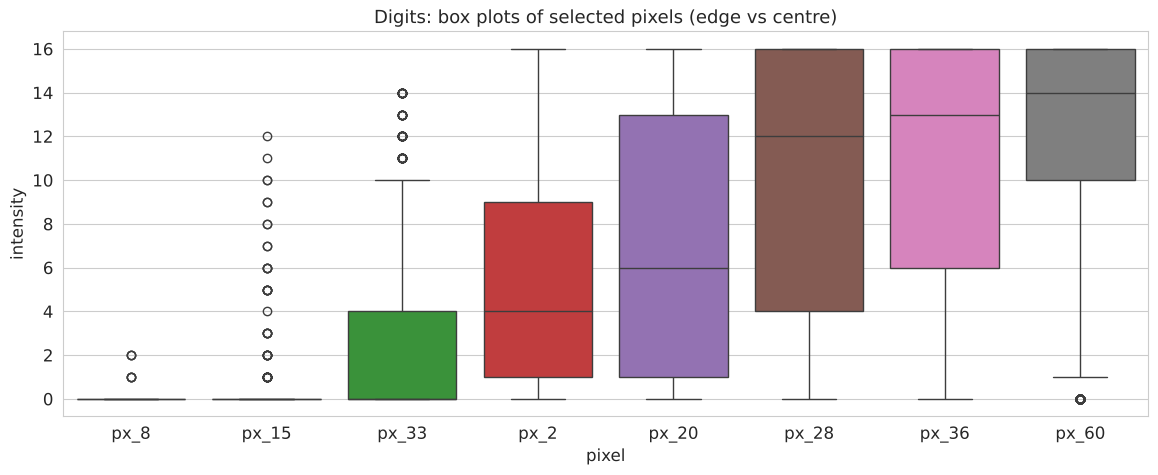

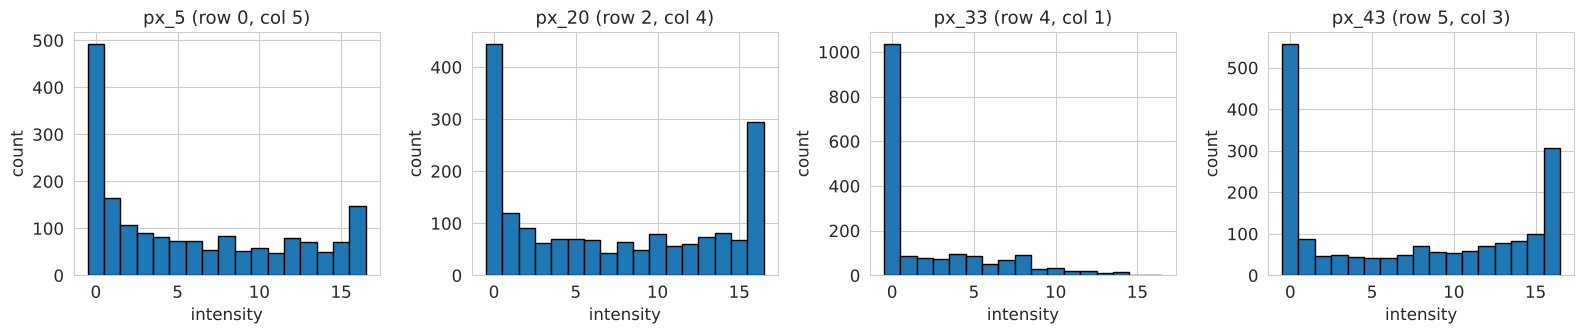

In [14]:
# Individual pixels: box plots (edge vs centre) + histograms
sample_px = [8, 15, 33, 2, 20, 28, 36, 60]   # 8, 15 = side edges, 33 = near edge, rest = centre/top/bottom
plt.figure(figsize=(14, 5))
sns.boxplot(data=df_dig[[f"px_{i}" for i in sample_px]])
plt.title("Digits: box plots of selected pixels (edge vs centre)")
plt.xlabel("pixel")
plt.ylabel("intensity")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, p in zip(axes, [5, 20, 33, 43]):
    ax.hist(X_dig[:, p], bins=17, range=(-0.5, 16.5), edgecolor="black")
    ax.set_title(f"px_{p} (row {p // 8}, col {p % 8})")
    ax.set_xlabel("intensity")
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

Edge pixels are almost always 0, and centre pixels are bimodal (0 and 16). The outliers are valid values, so we keep them.

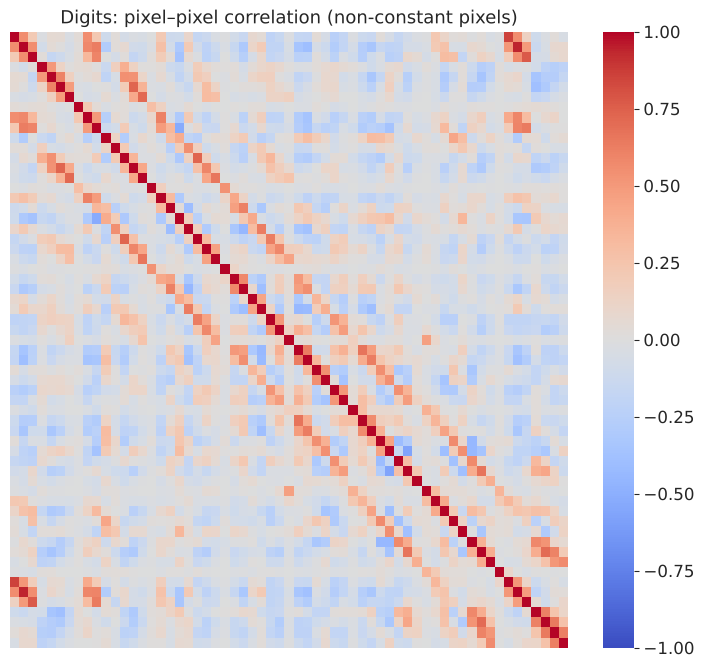

Pixel pairs with |r| > 0.7: 7 of 1830
Fraction of pairs with |r| < 0.3: 0.905
Strongest pair: px_2 and px_58 (r = 0.94)


In [15]:
# Pixel–pixel Pearson correlation (constant pixels removed)
pix_std = X_dig.std(axis=0)
corr_dig = np.corrcoef(X_dig[:, pix_std > 0], rowvar=False)  # constant pixels give undefined correlation
plt.figure(figsize=(9, 8))
sns.heatmap(corr_dig, cmap="coolwarm", vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title("Digits: pixel–pixel correlation (non-constant pixels)")
plt.show()

upper = corr_dig[np.triu_indices_from(corr_dig, k=1)]
print("Pixel pairs with |r| > 0.7:", (np.abs(upper) > 0.7).sum(), "of", len(upper))
print(f"Fraction of pairs with |r| < 0.3: {(np.abs(upper) < 0.3).mean():.3f}")

# Strongest pair (indices mapped back to the original 0-63 pixel numbering)
kept = np.where(pix_std > 0)[0]
iu = np.triu_indices_from(corr_dig, k=1)
top = np.argmax(np.abs(upper))
print(f"Strongest pair: px_{kept[iu[0][top]]} and px_{kept[iu[1][top]]} (r = {upper[top]:.2f})")

Pixels are mostly uncorrelated (7 of 1830 pairs have |r| > 0.7). The strongest pair is px_2–px_58 (r = 0.94).

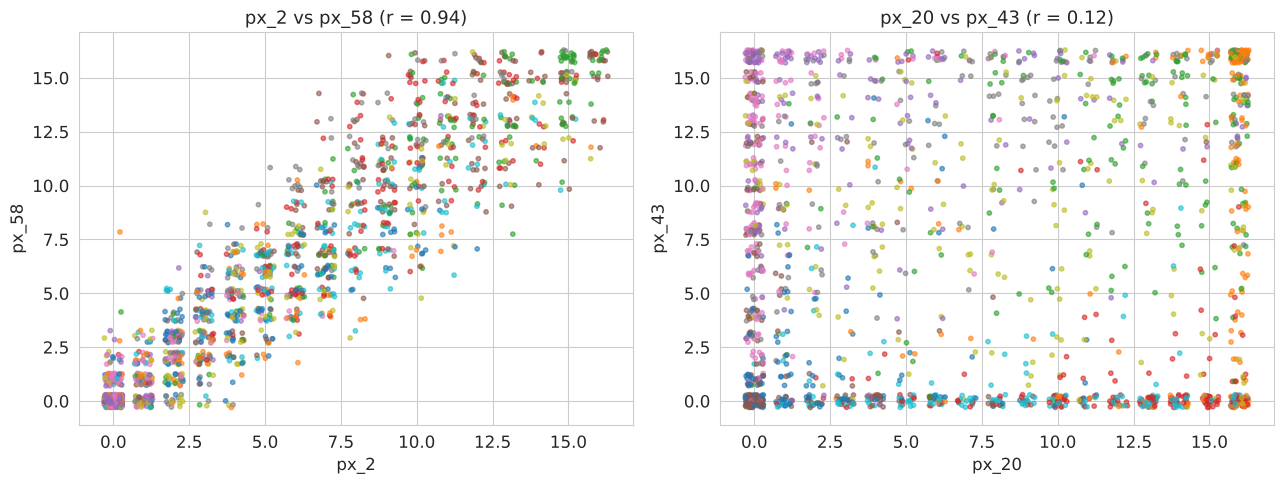

In [16]:
# scatter plots: the most correlated pair vs a pair with almost no correlation
# pixels only take 17 values, so we add a bit of noise (jitter) so the points don't stack
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (a, b) in zip(axes, [(2, 58), (20, 43)]):
    jx = X_dig[:, a] + rng.uniform(-0.3, 0.3, len(X_dig))
    jy = X_dig[:, b] + rng.uniform(-0.3, 0.3, len(X_dig))
    ax.scatter(jx, jy, c=y_dig, cmap="tab10", s=10, alpha=0.6)
    r = np.corrcoef(X_dig[:, a], X_dig[:, b])[0, 1]
    ax.set(xlabel=f"px_{a}", ylabel=f"px_{b}", title=f"px_{a} vs px_{b} (r = {r:.2f})")
plt.tight_layout()
plt.show()


## Task 2: Models from scratch vs scikit-learn
70/30 split (`random_state=42`). Hyperparameters are chosen by 5-fold CV on the training set.

In [17]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

RANDOM_STATE = 42
# same folds for every model so CV scores are comparable
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 2(a) Regression: Diabetes

In [18]:
# 70/30 split, then standardise (fit on train only)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
scaler_reg = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler_reg.transform(X_train), scaler_reg.transform(X_test)

# largest eigenvalue tells us the max learning rate before GD blows up
lam_max = np.linalg.eigvalsh(X_train_s.T @ X_train_s / len(X_train_s)).max()
print(f"lambda_max = {lam_max:.3f}  ->  stable if lr < {2 / lam_max:.3f}")

lambda_max = 3.957  ->  stable if lr < 0.505


In [19]:
class ElasticNetRegression():

    def __init__(self, learning_rate, iterations, penalty):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l1_penalty = self.l2_penalty = penalty   # lambda_1 = lambda_2 = lambda

    def fit(self, X, Y):
        self.m, self.n = X.shape
        self.W, self.b = np.zeros(self.n), 0.0   # start from zero weights
        self.X, self.Y = X, Y
        self.loss_history = []
        for _ in range(self.iterations):
            self.update_weights()
            r = Y - self.predict(X)
            # save the objective so we can plot convergence later
            self.loss_history.append(0.5 * np.mean(r ** 2) + self.l1_penalty * np.abs(self.W).sum()
                                     + 0.5 * self.l2_penalty * self.W @ self.W)
        return self

    def update_weights(self):
        r = self.Y - self.predict(self.X)
        # MSE gradient + L1 subgradient + L2 term
        dW = -self.X.T @ r / self.m + self.l1_penalty * np.sign(self.W) + self.l2_penalty * self.W
        self.W = self.W - self.learning_rate * dW
        self.b = self.b + self.learning_rate * r.mean()   # bias isn't penalised

    def predict(self, X):
        return X @ self.W + self.b


class LassoRegression():

    def __init__(self, learning_rate, iterations, penalty):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l1_penalty = penalty

    def fit(self, X, Y):
        self.m, self.n = X.shape
        self.W, self.b = np.zeros(self.n), 0.0
        self.X, self.Y = X, Y
        self.loss_history = []
        for _ in range(self.iterations):
            self.update_weights()
            r = Y - self.predict(X)
            self.loss_history.append(0.5 * np.mean(r ** 2) + self.l1_penalty * np.abs(self.W).sum())
        return self

    # shrinks towards 0 and sets small values to exactly 0
    def soft_threshold(self, v, kappa):
        return np.sign(v) * np.maximum(np.abs(v) - kappa, 0.0)

    def update_weights(self):
        r = self.Y - self.predict(self.X)
        # normal gradient step on the MSE, then soft threshold for the L1 part
        W_half = self.W + self.learning_rate * self.X.T @ r / self.m
        self.W = self.soft_threshold(W_half, self.learning_rate * self.l1_penalty)
        self.b = self.b + self.learning_rate * r.mean()

    def predict(self, X):
        return X @ self.W + self.b

#### Learning rate and iterations (λ = 1)

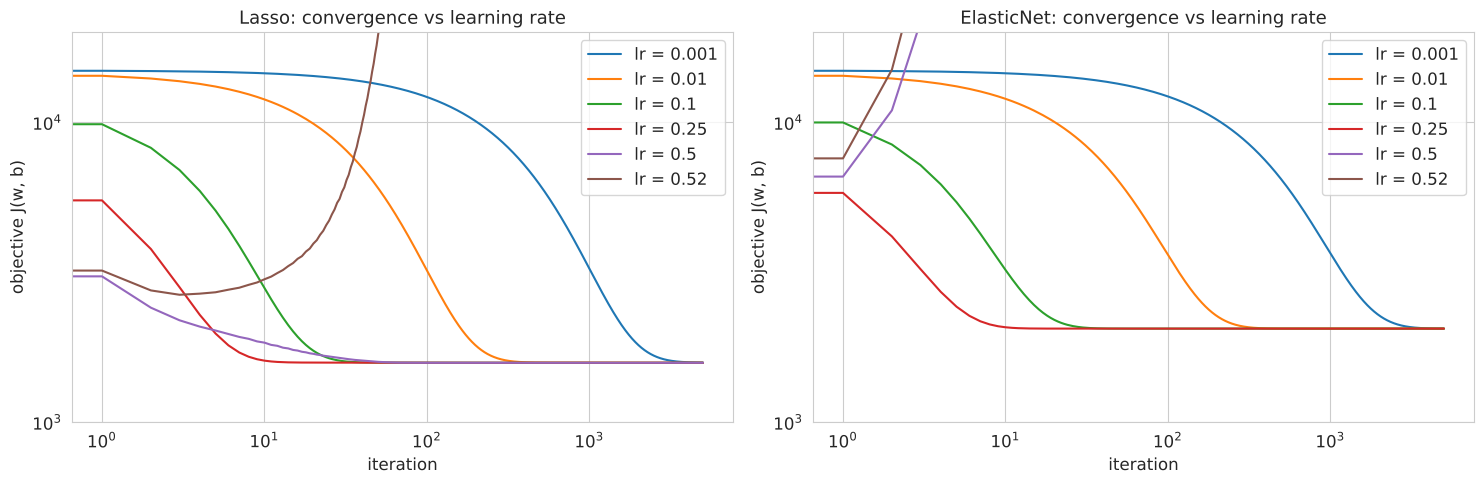

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# try a range of learning rates (0.52 is just past the stability limit)
for lr in [0.001, 0.01, 0.1, 0.25, 0.5, 0.52]:
    with np.errstate(over="ignore", invalid="ignore"):
        for ax, mdl in zip(axes, [LassoRegression(lr, 5000, 1.0), ElasticNetRegression(lr, 5000, 1.0)]):
            h = np.array(mdl.fit(X_train_s, y_train).loss_history)
            ax.plot(np.where(h < 1e6, h, np.nan), label=f"lr = {lr}")   # hide diverged runs
for ax, name in zip(axes, ["Lasso", "ElasticNet"]):
    ax.set(xscale="log", yscale="log", ylim=(1e3, 2e4), xlabel="iteration", ylabel="objective J(w, b)",
           title=f"{name}: convergence vs learning rate")
    ax.legend()
plt.tight_layout(); plt.show()

Lasso diverges above η ≈ 0.5 and ElasticNet above η ≈ 0.4. We use η = 0.25 and 5000 iterations.

#### Penalty (coefficient paths)

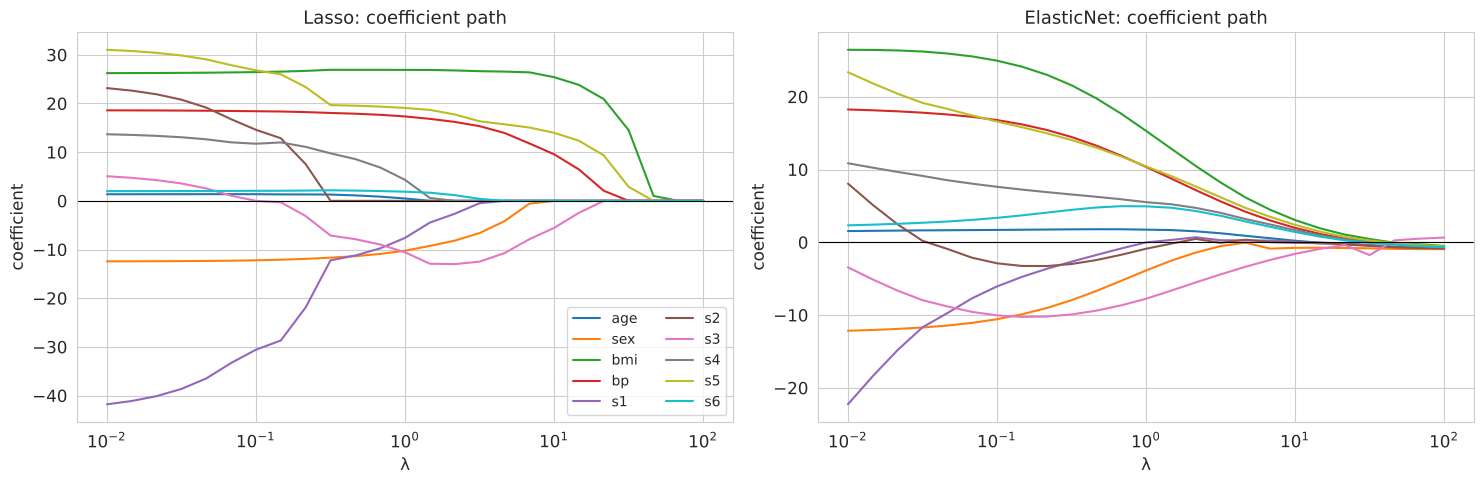

Lasso: smallest λ at which each weight is exactly 0:
s3      0.100
s2      0.316
age     1.468
s4      2.154
s1      4.642
s6      4.642
sex    10.000
bp     31.623
s5     46.416
bmi    68.129


,λ,Lasso: # zero weights,ElasticNet: # zero weights
0,0.010,0,0
3,0.032,0,0
6,0.100,1,0
9,0.316,1,0
12,1.000,1,0
15,3.162,3,0
18,10.000,6,0
21,31.623,8,0
24,100.000,10,0


In [21]:
# ElasticNet needs a smaller lr when lambda is big, otherwise it diverges
def enet_lr(lam):
    return min(0.25, 1 / (lam_max + lam))

lambdas = np.logspace(-2, 2, 25)   # 0.01 to 100
paths = {"Lasso": [LassoRegression(0.25, 5000, lam).fit(X_train_s, y_train).W for lam in lambdas],
         "ElasticNet": [ElasticNetRegression(enet_lr(lam), 5000, lam).fit(X_train_s, y_train).W
                        for lam in lambdas]}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, W) in zip(axes, paths.items()):
    ax.plot(lambdas, np.array(W))
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xscale="log", xlabel="λ", ylabel="coefficient", title=f"{name}: coefficient path")
axes[0].legend(feats, ncol=2, fontsize=10)
plt.tight_layout(); plt.show()

# find where each Lasso weight first hits 0
W_lasso = np.array(paths["Lasso"])
first_zero = {f: lambdas[np.argmax(W_lasso[:, k] == 0)] if (W_lasso[:, k] == 0).any() else np.nan
              for k, f in enumerate(feats)}
print("Lasso: smallest λ at which each weight is exactly 0:")
print(pd.Series(first_zero).sort_values().round(3).to_string())

pd.DataFrame({"λ": lambdas.round(3),
              "Lasso: # zero weights": [int((w == 0).sum()) for w in paths["Lasso"]],
              "ElasticNet: # zero weights": [int((w == 0).sum()) for w in paths["ElasticNet"]]}).iloc[::3]

As λ grows, Lasso sets weights to exactly 0. s3 touches 0 at λ = 0.1 only because it changes sign there; s2 is the first weight that stays at 0 (from λ ≈ 0.32). ElasticNet shows no exact zeros, but this is an artefact of our plain subgradient update (`np.sign(W)`): the weights oscillate around 0 instead of landing on it. The true ElasticNet solution has the same zero condition as Lasso for the L1 part, so all weights should be 0 for λ above ≈ 47; in our path they only shrink to small values (≈ ±0.5 at λ = 100).

#### Tuning λ (5-fold CV)

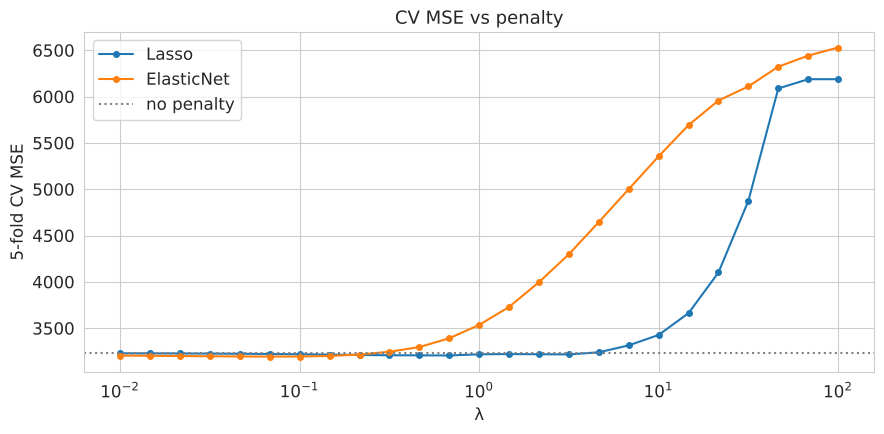

Lasso: λ = 0.681 (CV MSE 3205)   ElasticNet: λ = 0.068 (CV MSE 3193)   No penalty: CV MSE 3230


In [22]:
# average validation MSE over the 5 folds
def cv_mse(make_model, X, y):
    return np.mean([mean_squared_error(y[va], make_model().fit(X[tr], y[tr]).predict(X[va]))
                    for tr, va in kf.split(X)])

cv = pd.DataFrame({"Lasso": [cv_mse(lambda: LassoRegression(0.25, 5000, lam), X_train_s, y_train) for lam in lambdas],
                   "ElasticNet": [cv_mse(lambda: ElasticNetRegression(enet_lr(lam), 5000, lam), X_train_s, y_train)
                                  for lam in lambdas]}, index=lambdas)
# pick lambda with lowest CV error, and compare to no penalty
best_lam, best_lam_en = cv["Lasso"].idxmin(), cv["ElasticNet"].idxmin()
no_pen = cv_mse(lambda: LassoRegression(0.25, 5000, 0.0), X_train_s, y_train)

ax = cv.plot(marker="o", ms=4, logx=True, figsize=(9, 4.5))
ax.axhline(no_pen, color="gray", ls=":", label="no penalty")
ax.set(xlabel="λ", ylabel="5-fold CV MSE", title="CV MSE vs penalty"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Lasso: λ = {best_lam:.3f} (CV MSE {cv['Lasso'].min():.0f})   "
      f"ElasticNet: λ = {best_lam_en:.3f} (CV MSE {cv['ElasticNet'].min():.0f})   No penalty: CV MSE {no_pen:.0f}")

Best λ: Lasso 0.68, ElasticNet 0.068 (≈ 1% better than no penalty).

#### Test results vs `LinearRegression`

                   train MSE  test MSE  test R²
LinearRegression    2924.046  2821.751    0.477
Lasso (ours)        2948.089  2796.622    0.482
ElasticNet (ours)   2953.571  2809.303    0.480
Mean-only baseline test MSE: 5433


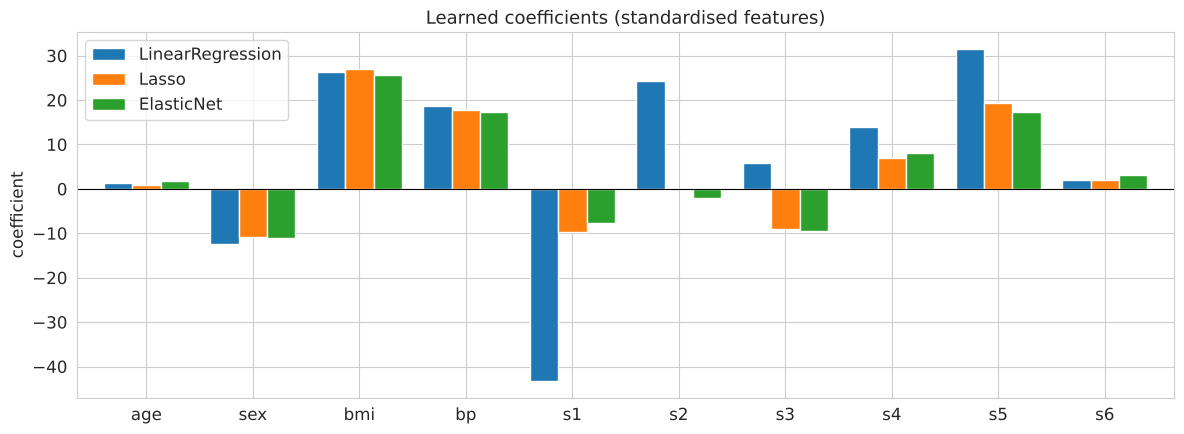

,LinearRegression,Lasso,ElasticNet
age,1.35,0.86,1.68
sex,-12.45,-10.91,-11.07
bmi,26.21,26.91,25.54
bp,18.61,17.67,17.24
s1,-43.26,-9.76,-7.69
s2,24.26,-0.00,-2.12
s3,5.74,-8.97,-9.57
s4,13.96,6.85,8.05
s5,31.58,19.36,17.42
s6,1.98,2.01,3.08


In [23]:
# refit on the full training set with the best lambdas
lasso = LassoRegression(0.25, 5000, best_lam).fit(X_train_s, y_train)
enet = ElasticNetRegression(enet_lr(best_lam_en), 5000, best_lam_en).fit(X_train_s, y_train)
linreg = LinearRegression().fit(X_train_s, y_train)

reg_models = {"LinearRegression": linreg, "Lasso (ours)": lasso, "ElasticNet (ours)": enet}
print(pd.DataFrame({n: {"train MSE": mean_squared_error(y_train, m.predict(X_train_s)),
                        "test MSE": mean_squared_error(y_test, m.predict(X_test_s)),
                        "test R²": r2_score(y_test, m.predict(X_test_s))}
                    for n, m in reg_models.items()}).T.round(3))
print(f"Mean-only baseline test MSE: {mean_squared_error(y_test, np.full_like(y_test, y_train.mean())):.0f}")

# compare learned coefficients side by side
coefs = pd.DataFrame({"LinearRegression": linreg.coef_, "Lasso": lasso.W, "ElasticNet": enet.W}, index=feats)
ax = coefs.plot(kind="bar", figsize=(12, 4.5), width=0.8, rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set(ylabel="coefficient", title="Learned coefficients (standardised features)")
plt.tight_layout(); plt.show()
coefs.round(2)

Test MSE: Lasso 2797 < ElasticNet 2809 < LinearRegression 2822. The gains are small because OLS barely overfits.

### 2(b) Classification: Digits

In [24]:
# same split/scaling idea as regression, plus one-hot labels for the MLP
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_dig, y_dig, test_size=0.3, random_state=RANDOM_STATE)
scaler_dig = StandardScaler().fit(Xd_train)
Xd_train_s, Xd_test_s = scaler_dig.transform(Xd_train), scaler_dig.transform(Xd_test)
Yd_train_oh = OneHotEncoder(sparse_output=False).fit_transform(yd_train.reshape(-1, 1))

# returns (mean val acc, mean train acc) over 5 folds
def cv_accuracy(make_model, X, y, Y_oh=None, epochs=None):
    va, tr_acc = [], []
    for tr, te in kf.split(X):
        mdl = make_model()
        mdl.fit(X[tr], y[tr]) if Y_oh is None else mdl.fit(X[tr], Y_oh[tr], epochs)
        va.append(accuracy_score(y[te], mdl.predict(X[te])))
        tr_acc.append(accuracy_score(y[tr], mdl.predict(X[tr])))
    return np.mean(va), np.mean(tr_acc)

#### (a) Multiclass SVM (one-vs-rest)

In [25]:
class MulticlassSVM():

    def __init__(self, learning_rate, lambda_param, n_iters):
        self.learning_rate = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters
        self.W, self.b = None, None   # one weight column and bias per class
        self.losses = None            # objective J at each iteration, one row per class

    def fit(self, X, y):
        m, n = X.shape
        self.classes = np.unique(y)
        self.W, self.b = np.zeros((n, len(self.classes))), np.zeros(len(self.classes))
        self.losses = np.zeros((len(self.classes), self.n_iters))
        for k, c in enumerate(self.classes):
            y_bin = np.where(y == c, 1.0, -1.0)   # one-vs-rest labels: +1 for class c, -1 for the rest
            w, b = np.zeros(n), 0.0
            for t in range(self.n_iters):
                margins = y_bin * (X @ w + b)
                S = margins < 1                    # margin violators: the only points with a hinge gradient
                self.losses[k, t] = self.lambda_param * w @ w + np.maximum(0, 1 - margins).mean()
                grad_w = 2 * self.lambda_param * w - X[S].T @ y_bin[S] / m
                grad_b = -y_bin[S].sum() / m
                w -= self.learning_rate * grad_w
                b -= self.learning_rate * grad_b
            self.W[:, k], self.b[k] = w, b
        return self

    def predict(self, X):
        # score of every class, then pick the class with the highest score
        return self.classes[np.argmax(X @ self.W + self.b, axis=1)]


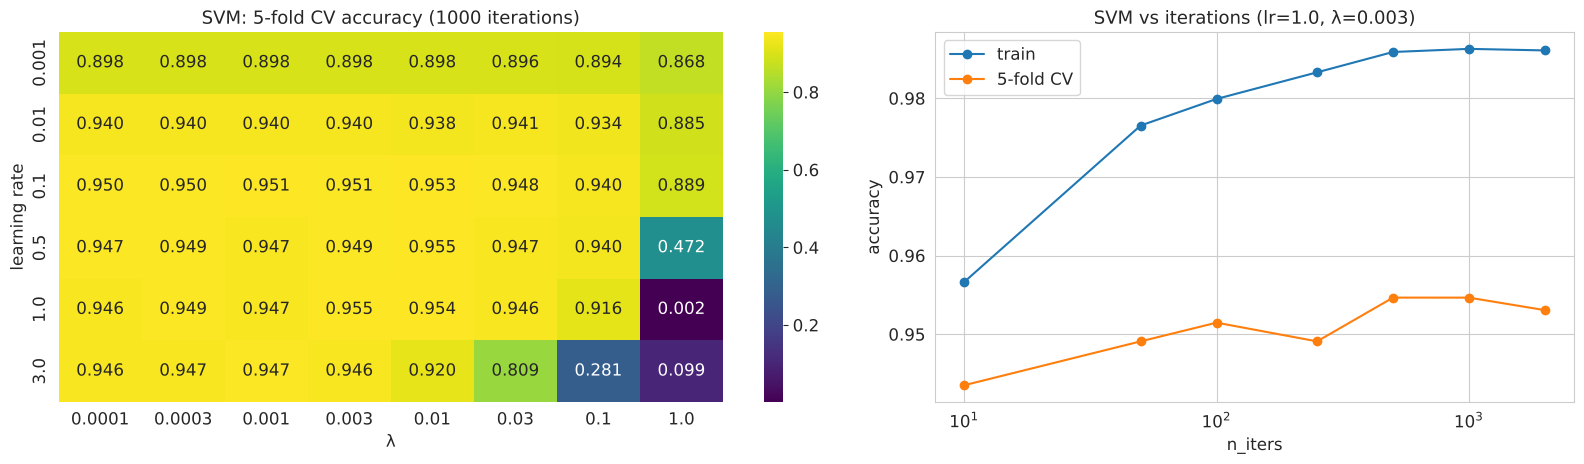

Best: lr = 1.0, λ = 0.003, n_iters = 500  |  CV acc = 0.9547, train acc = 0.9825, test acc = 0.9667


In [26]:
# grid search over lr and lambda first
svm_lrs = [0.001, 0.01, 0.1, 0.5, 1.0, 3.0]
svm_lams = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
with np.errstate(over="ignore", invalid="ignore"):
    svm_cv = pd.DataFrame([[cv_accuracy(lambda: MulticlassSVM(lr, lam, 1000), Xd_train_s, yd_train)[0]
                            for lam in svm_lams] for lr in svm_lrs], index=svm_lrs, columns=svm_lams)
svm_lr, svm_lam = svm_cv.stack().idxmax()

# then check how many iterations we actually need
iters_grid = [10, 50, 100, 250, 500, 1000, 2000]
svm_iter = np.array([cv_accuracy(lambda: MulticlassSVM(svm_lr, svm_lam, it), Xd_train_s, yd_train)
                     for it in iters_grid])
svm_n_iters = iters_grid[svm_iter[:, 0].argmax()]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(svm_cv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set(xlabel="λ", ylabel="learning rate", title="SVM: 5-fold CV accuracy (1000 iterations)")
axes[1].plot(iters_grid, svm_iter[:, 1], marker="o", label="train")
axes[1].plot(iters_grid, svm_iter[:, 0], marker="o", label="5-fold CV")
axes[1].set(xscale="log", xlabel="n_iters", ylabel="accuracy", title=f"SVM vs iterations (lr={svm_lr}, λ={svm_lam})")
axes[1].legend()
plt.tight_layout(); plt.show()

# final model with the best settings
svm = MulticlassSVM(svm_lr, svm_lam, svm_n_iters).fit(Xd_train_s, yd_train)
print(f"Best: lr = {svm_lr}, λ = {svm_lam}, n_iters = {svm_n_iters}  |  CV acc = {svm_iter[:, 0].max():.4f}, "
      f"train acc = {accuracy_score(yd_train, svm.predict(Xd_train_s)):.4f}, "
      f"test acc = {accuracy_score(yd_test, svm.predict(Xd_test_s)):.4f}")

Best: η = 1, λ = 0.003, 500 iterations → **test accuracy 96.7%**.

#### SVM training loss

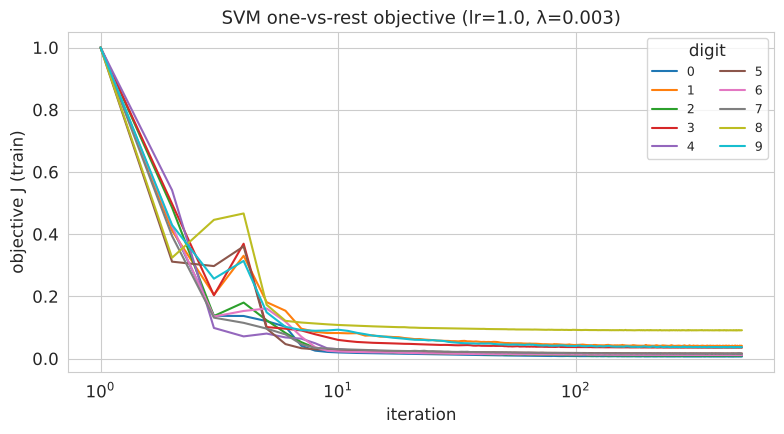

Final J per class: [0.0066 0.041  0.0094 0.035  0.0115 0.0167 0.0114 0.0151 0.0911 0.0371]


In [27]:
# one loss curve per one-vs-rest classifier
plt.figure(figsize=(8, 4.5))
for k in range(len(svm.classes)):
    plt.plot(np.arange(1, svm_n_iters + 1), svm.losses[k], label=str(svm.classes[k]))
plt.xscale("log")
plt.xlabel("iteration"); plt.ylabel("objective J (train)")
plt.title(f"SVM one-vs-rest objective (lr={svm_lr}, λ={svm_lam})")
plt.legend(title="digit", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
print("Final J per class:", np.round(svm.losses[:, -1], 4))

The loss has converged by ~100 iterations. Digit 8 is the hardest class to separate.

#### SVM decision boundaries (one-vs-rest scores, test set)

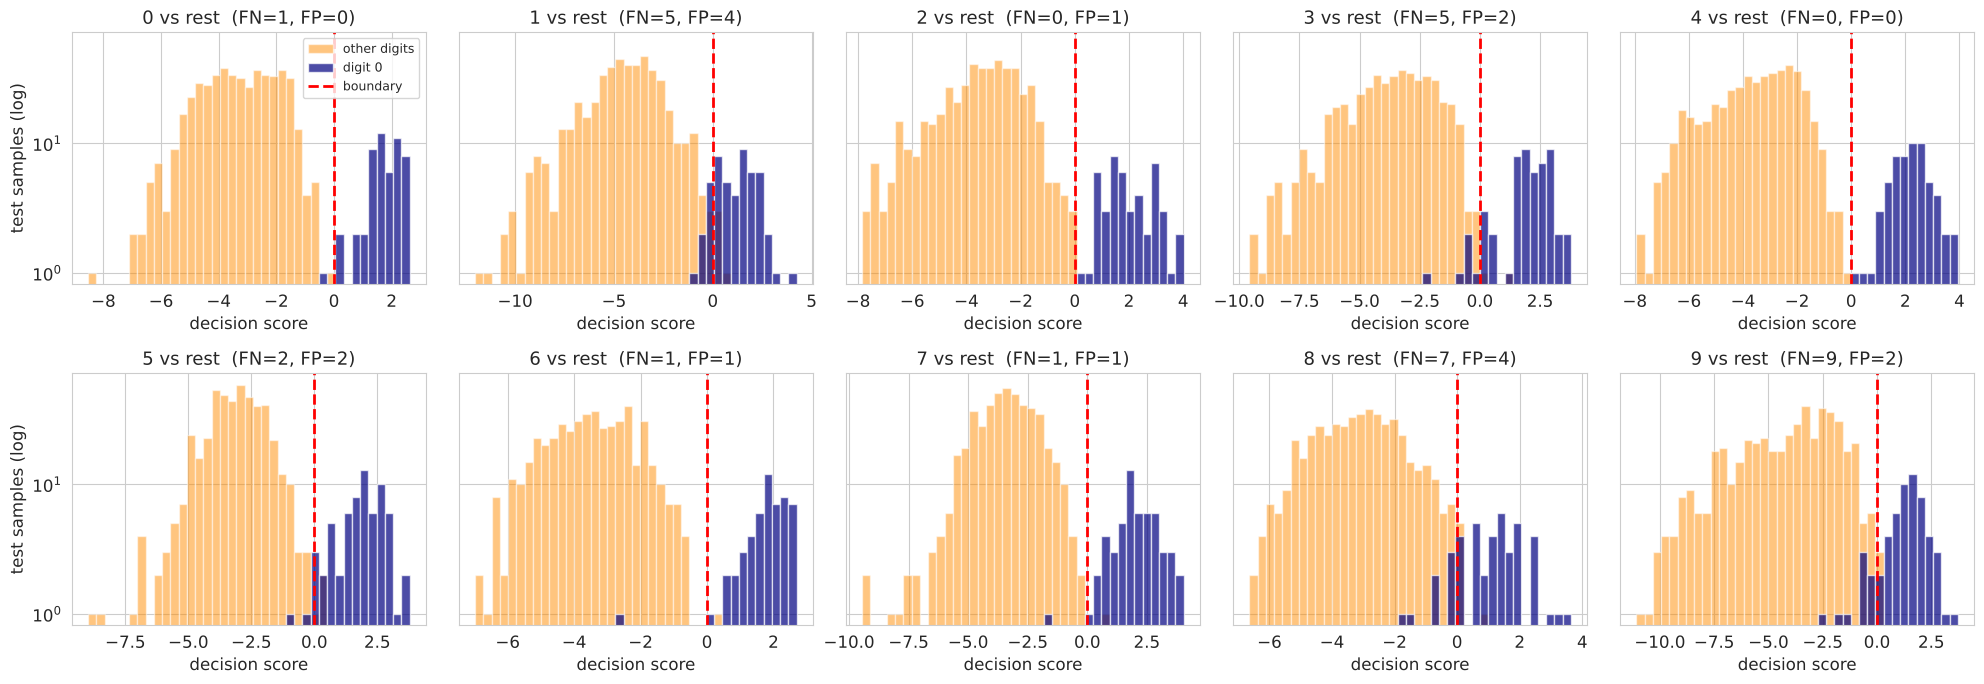

In [28]:
# raw scores for each class on the test set
test_scores = Xd_test_s @ svm.W + svm.b

fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for k, ax in enumerate(axes.flat):
    s = test_scores[:, k]
    bins = np.linspace(s.min(), s.max(), 40)
    ax.hist(s[yd_test != k], bins=bins, alpha=0.5, color="darkorange", label="other digits")
    ax.hist(s[yd_test == k], bins=bins, alpha=0.7, color="navy", label=f"digit {k}")
    ax.axvline(0, color="red", ls="--", lw=2, label="boundary")
    # count misses (FN) and false alarms (FP) for this binary classifier
    fn, fp = int(((s < 0) & (yd_test == k)).sum()), int(((s >= 0) & (yd_test != k)).sum())
    ax.set(title=f"{k} vs rest  (FN={fn}, FP={fp})", xlabel="decision score")
    ax.set_yscale("log")
axes[0, 0].set_ylabel("test samples (log)"); axes[1, 0].set_ylabel("test samples (log)")
axes[0, 0].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

Digits 0, 2, 4, 6 and 7 are cleanly separated, while 1, 3, 8 and 9 overlap the boundary the most.

#### SVM decision boundaries (2-D PCA projection)

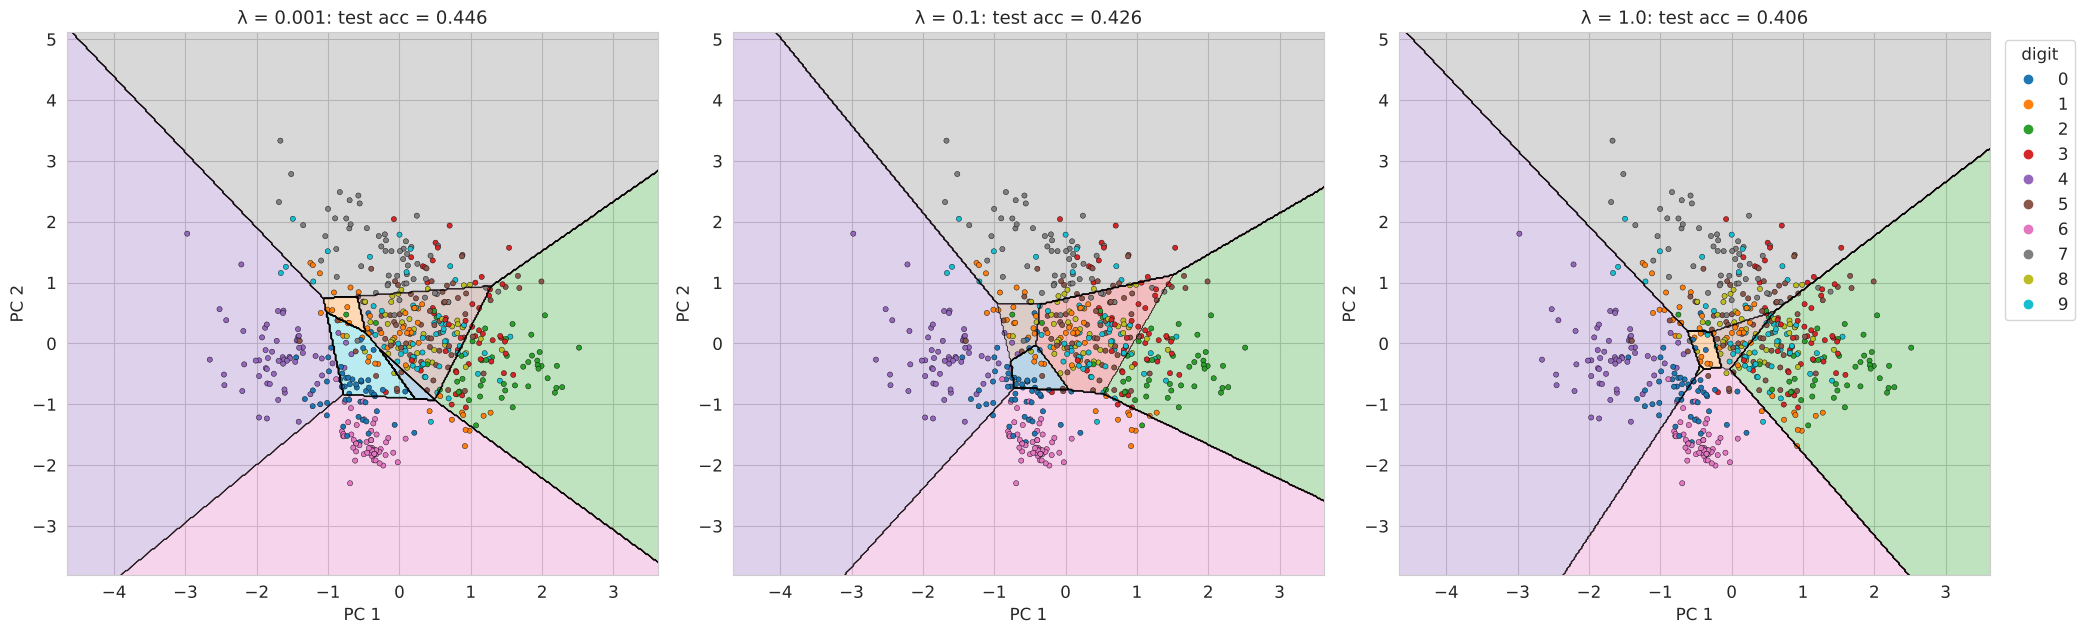

Variance explained by 2 PCs: 0.218


In [29]:
# can't plot 64-D, so project to 2 PCs and retrain the SVM there just to visualise
pca = PCA(n_components=2, whiten=True, random_state=RANDOM_STATE).fit(Xd_train_s)
Z_train, Z_test = pca.transform(Xd_train_s), pca.transform(Xd_test_s)
# grid of points to colour the decision regions
xx, yy = np.meshgrid(np.linspace(Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1, 400),
                     np.linspace(Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1, 400))
cmap = plt.get_cmap("tab10")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, lam in zip(axes, [0.001, 0.1, 1.0]):
    svm2d = MulticlassSVM(0.1, lam, 1000).fit(Z_train, yd_train)
    regions = svm2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=np.arange(-0.5, 10), cmap=cmap, alpha=0.3)
    ax.contour(xx, yy, regions, levels=np.arange(-0.5, 10), colors="k", linewidths=0.5)
    ax.scatter(Z_test[:, 0], Z_test[:, 1], c=yd_test, cmap=cmap, vmin=-0.5, vmax=9.5, s=14, edgecolor="k", lw=0.3)
    ax.set(xlabel="PC 1", ylabel="PC 2",
           title=f"λ = {lam}: test acc = {accuracy_score(yd_test, svm2d.predict(Z_test)):.3f}")
handles = [plt.Line2D([], [], marker="o", ls="", color=cmap(d), label=str(d)) for d in range(10)]
axes[2].legend(handles=handles, title="digit", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
print(f"Variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.3f}")

The boundaries are linear. 2 PCs keep only 22% of the variance, so accuracy is ≈ 41–45%.

#### (b) Multilayer Perceptron (MLP)

In [30]:
class MLP():

    def __init__(self, input_size, hidden_size, output_size, lr, random_state=RANDOM_STATE):
        rng = np.random.default_rng(random_state)   # seeded weight init -> reproducible runs
        self.lr = lr
        self.W1 = rng.normal(0, np.sqrt(2 / input_size), (input_size, hidden_size))
        self.b1 = np.zeros(hidden_size)
        self.W2 = rng.normal(0, np.sqrt(2 / hidden_size), (hidden_size, output_size))
        self.b2 = np.zeros(output_size)

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(float)

    def softmax(self, Z):
        expZ = np.exp(Z - Z.max(axis=1, keepdims=True))   # shift for numerical stability
        return expZ / expZ.sum(axis=1, keepdims=True)

    def forward(self, X):
        Z1 = X @ self.W1 + self.b1
        A1 = self.relu(Z1)
        return Z1, A1, self.softmax(A1 @ self.W2 + self.b2)

    def fit(self, X, y, epochs):
        # y is the one-hot encoded label matrix (m x 10)
        m = X.shape[0]
        self.losses = []
        for _ in range(epochs):
            Z1, A1, Y_hat = self.forward(X)                                 # forward pass
            self.losses.append(-np.sum(y * np.log(Y_hat + 1e-12)) / m)      # cross-entropy loss L
            dZ2 = (Y_hat - y) / m                                            # dL/d(output logits)
            dZ1 = (dZ2 @ self.W2.T) * self.relu_derivative(Z1)               # backpropagate through ReLU
            self.W2 -= self.lr * A1.T @ dZ2                                  # gradient descent updates
            self.b2 -= self.lr * dZ2.sum(axis=0)
            self.W1 -= self.lr * X.T @ dZ1
            self.b1 -= self.lr * dZ1.sum(axis=0)
        return self

    def predict(self, X):
        return np.argmax(self.forward(X)[2], axis=1)

#### MLP tuning (5-fold CV)

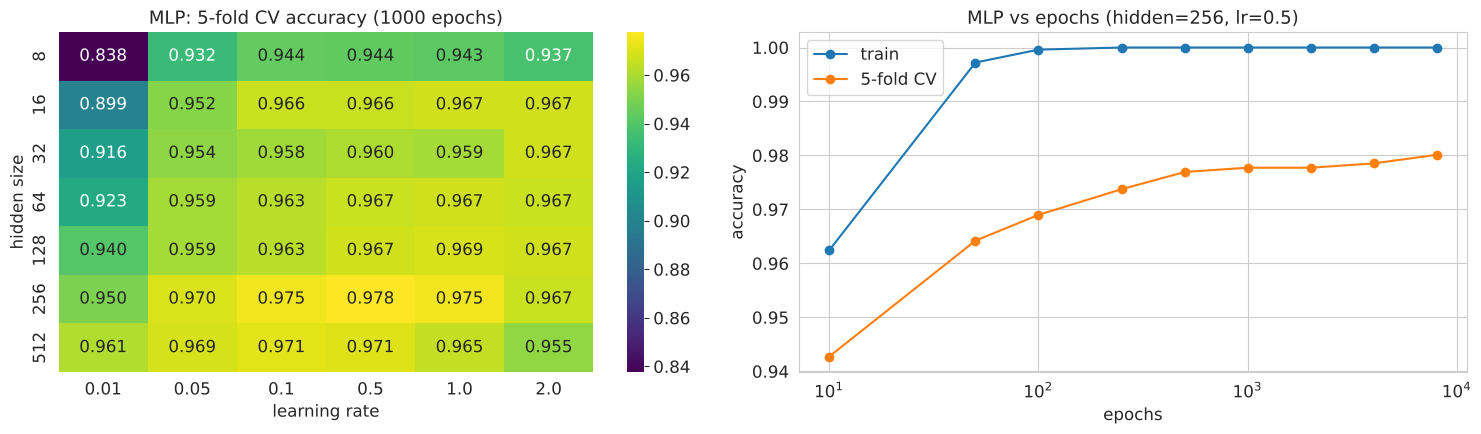

Best: hidden = 256, lr = 0.5, epochs = 8000  |  CV acc = 0.9801, train acc = 1.0000, test acc = 0.9796


In [31]:
# grid search over hidden size and lr (1000 epochs each)
hidden_grid, mlp_lrs = [8, 16, 32, 64, 128, 256, 512], [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
mlp_cv = pd.DataFrame([[cv_accuracy(lambda: MLP(64, h, 10, lr), Xd_train_s, yd_train, Yd_train_oh, 1000)[0]
                        for lr in mlp_lrs] for h in hidden_grid], index=hidden_grid, columns=mlp_lrs)
mlp_h, mlp_lr = mlp_cv.stack().idxmax()

# then tune number of epochs with the best combo
epoch_grid = [10, 50, 100, 250, 500, 1000, 2000, 4000, 8000]
mlp_ep = np.array([cv_accuracy(lambda: MLP(64, mlp_h, 10, mlp_lr), Xd_train_s, yd_train, Yd_train_oh, ep)
                   for ep in epoch_grid])
mlp_epochs = epoch_grid[mlp_ep[:, 0].argmax()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(mlp_cv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set(xlabel="learning rate", ylabel="hidden size", title="MLP: 5-fold CV accuracy (1000 epochs)")
axes[1].plot(epoch_grid, mlp_ep[:, 1], marker="o", label="train")
axes[1].plot(epoch_grid, mlp_ep[:, 0], marker="o", label="5-fold CV")
axes[1].set(xscale="log", xlabel="epochs", ylabel="accuracy", title=f"MLP vs epochs (hidden={mlp_h}, lr={mlp_lr})")
axes[1].legend()
plt.tight_layout(); plt.show()

# final MLP
mlp = MLP(64, mlp_h, 10, mlp_lr).fit(Xd_train_s, Yd_train_oh, mlp_epochs)
print(f"Best: hidden = {mlp_h}, lr = {mlp_lr}, epochs = {mlp_epochs}  |  CV acc = {mlp_ep[:, 0].max():.4f}, "
      f"train acc = {accuracy_score(yd_train, mlp.predict(Xd_train_s)):.4f}, "
      f"test acc = {accuracy_score(yd_test, mlp.predict(Xd_test_s)):.4f}")

Best: 256 hidden units, η = 0.5, 8000 epochs → **test accuracy 98.0%**.

#### MLP training loss

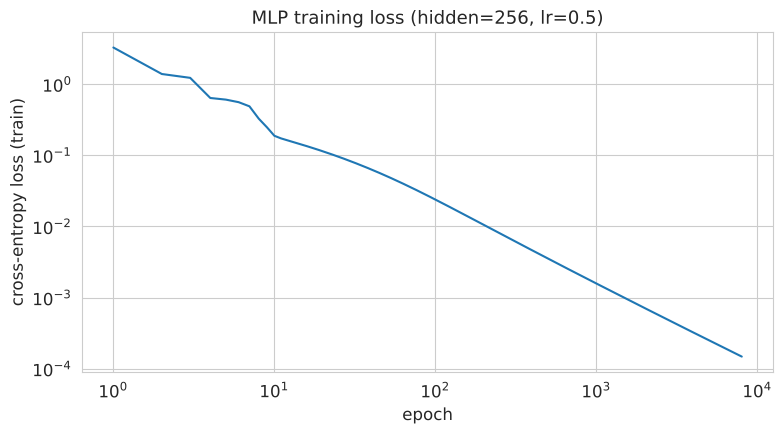

Loss at epoch 1000: 0.00158, 4000: 0.00032, 8000: 0.00015


In [32]:
# training loss of the final MLP (log-log so it's easier to see)
plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, mlp_epochs + 1), mlp.losses)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss (train)")
plt.title(f"MLP training loss (hidden={mlp_h}, lr={mlp_lr})")
plt.tight_layout(); plt.show()
print(f"Loss at epoch 1000: {mlp.losses[999]:.5f}, 4000: {mlp.losses[3999]:.5f}, {mlp_epochs}: {mlp.losses[-1]:.5f}")

The loss decreases steadily, with no instability.

#### (c) Comparison with `RandomForestClassifier` (tuned with `GridSearchCV`)

Best RF: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
                        CV acc  train acc  test acc  test errors
Multiclass SVM (ours)   0.9547     0.9825    0.9667         18.0
MLP (ours)              0.9801     1.0000    0.9796         11.0
RandomForest (sklearn)  0.9745     1.0000    0.9722         15.0


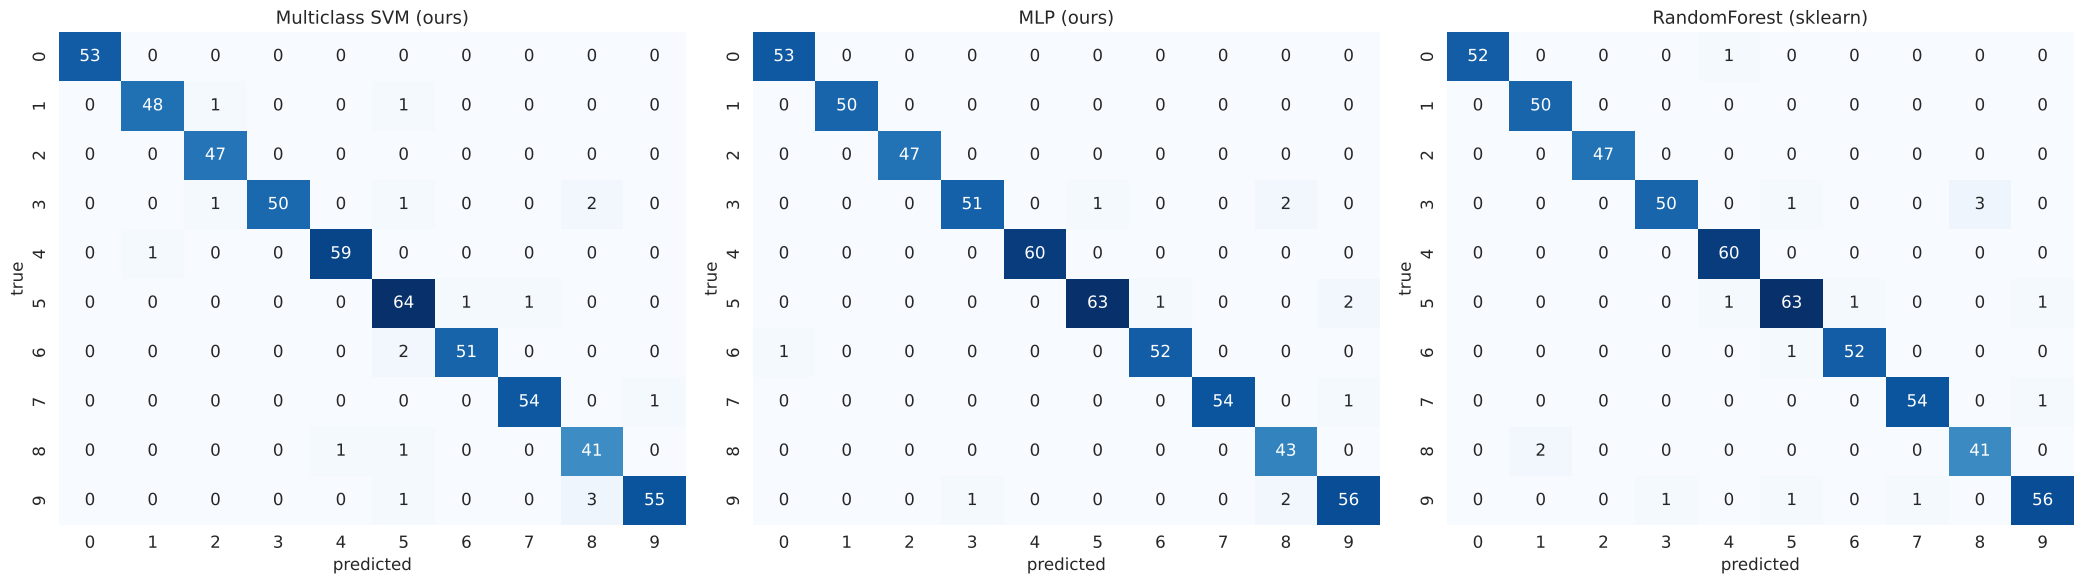

In [33]:
# small grid search for the random forest (sklearn)
rf_param_grid = {"n_estimators": [50, 100, 300], "max_depth": [None, 10, 20],
                 "max_features": ["sqrt", "log2"], "min_samples_leaf": [1, 2]}
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_param_grid, cv=kf,
                         scoring="accuracy", n_jobs=-1).fit(Xd_train_s, yd_train)
rf = rf_search.best_estimator_
print("Best RF:", rf_search.best_params_)

# put all three classifiers in one table
clf_models = {"Multiclass SVM (ours)": svm, "MLP (ours)": mlp, "RandomForest (sklearn)": rf}
cv_best = [svm_iter[:, 0].max(), mlp_ep[:, 0].max(), rf_search.best_score_]
print(pd.DataFrame({n: {"CV acc": cv, "train acc": accuracy_score(yd_train, m.predict(Xd_train_s)),
                        "test acc": accuracy_score(yd_test, m.predict(Xd_test_s)),
                        "test errors": int((m.predict(Xd_test_s) != yd_test).sum())}
                    for (n, m), cv in zip(clf_models.items(), cv_best)}).T.round(4))

# confusion matrices to see which digits get mixed up
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, m) in zip(axes, clf_models.items()):
    sns.heatmap(confusion_matrix(yd_test, m.predict(Xd_test_s)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(xlabel="predicted", ylabel="true", title=name)
plt.tight_layout(); plt.show()

MLP (98.0%) > RandomForest (97.2%) > SVM (96.7%).

## Task 3: Predicting tomorrow's S&P 500 returns
The models are retrained every year on a rolling window. Validation: 2001–2010. Test: 2011–2013.

### LLM use
We used an LLM to understand Task 3 before writing the code, with the prompt:

> *"Explain Task 3 of this assignment step by step so I understand the expectations. For each equation, explain what it computes and why it is used."*

We also used Claude to check the notebook against the assignment instructions multiple times and to edit a few cells (Sharpe and PnL over 2001–2013 plots, markdown findings and missing requirements check).

In [34]:
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

# all files are indexed by date, one column per permno
ret = pd.read_csv("eq_returns.csv", index_col=0, parse_dates=True)
ind = pd.read_csv("eq_indicator.csv", index_col=0, parse_dates=True)
bull = pd.read_csv("psych_bullish.csv", index_col=0, parse_dates=True)
bear = pd.read_csv("psych_bearish.csv", index_col=0, parse_dates=True)
member = ind == 1

print("Returns:", ret.shape, ret.index.min().date(), "to", ret.index.max().date())
print("Sentiment:", bull.shape, bull.index.min().date(), "to", bull.index.max().date())
print("Members per day: min", member.sum(axis=1).min(), " max", member.sum(axis=1).max())
print("Return values available for non-members:", int((ret.notna() & ~member).sum().sum()))
print("Missing returns for members:", int((ret.isna() & member).sum().sum()))
print("Duplicated permno columns (renamed by pandas):", int(ret.columns.str.contains(r"\.").sum()))

Returns: (8577, 1335) 1980-01-02 to 2013-12-31
Sentiment: (2068, 606) 2009-07-10 to 2015-06-07
Members per day: min 489  max 500
Return values available for non-members: 2190592


Missing returns for members: 0
Duplicated permno columns (renamed by pandas): 21


There are ~500 members per day and no missing returns for members. The 21 duplicated permnos are treated as separate series.

### 3(a) Volatility adjustment
EWMA filters with β1 = 0.97, β2 = 0.99 and a 60-day burn-in.

In [35]:
def ewma_vol(R, b1=0.97, b2=0.99, burn=60):
    R = R.values
    T, N = R.shape
    mu, s2, count = np.zeros(N), np.full(N, np.nan), np.zeros(N)
    sigma = np.full((T, N), np.nan)
    for t in range(T):
        ok = ~np.isnan(R[t])
        s2[ok & np.isnan(s2)] = 0.02 ** 2              # starting guess for a new stock
        mu[ok] = (1 - b2) * R[t, ok] + b2 * mu[ok]     # Eq. 3
        a = R[t, ok] - mu[ok]
        s2[ok] = (1 - b1) * a ** 2 + b1 * s2[ok]       # Eq. 2
        count[ok] += 1
        sigma[t] = np.where(count >= burn, np.sqrt(s2), np.nan)
    return sigma

sigma = pd.DataFrame(ewma_vol(ret), index=ret.index, columns=ret.columns)
radj = ret / sigma.shift(1)    # use yesterday's volatility -> no look-ahead

print("Std of raw returns (members):", round(ret[member].stack().std(), 4))
print("Std of vol-adjusted returns (members):", round(radj[member].stack().std(), 3))

Std of raw returns (members): 0.0239


Std of vol-adjusted returns (members): 1.057


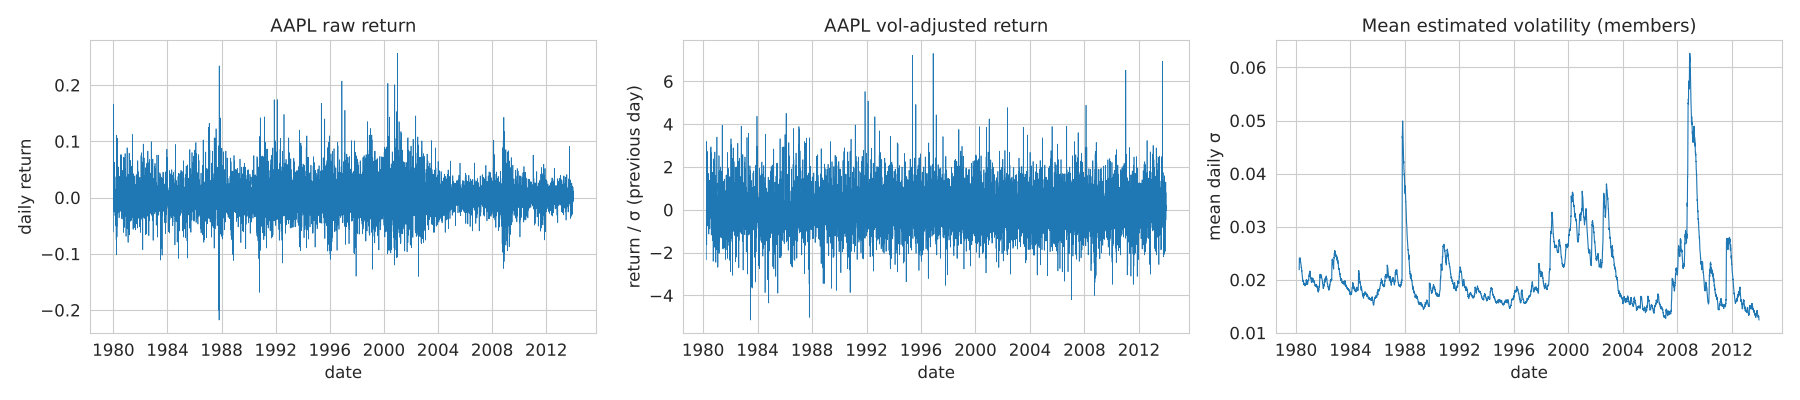

In [36]:
# example: AAPL (permno 14593)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(ret["14593"], lw=0.5); axes[0].set_title("AAPL raw return")
axes[0].set(xlabel="date", ylabel="daily return")
axes[1].plot(radj["14593"], lw=0.5); axes[1].set_title("AAPL vol-adjusted return")
axes[1].set(xlabel="date", ylabel="return / σ (previous day)")
# average volatility across members over time
axes[2].plot(sigma[member].mean(axis=1), lw=0.8); axes[2].set_title("Mean estimated volatility (members)")
axes[2].set(xlabel="date", ylabel="mean daily σ")
plt.tight_layout(); plt.show()

After adjustment, the returns are roughly stationary with std ≈ 1.

### 3(b) Features and target
Features for day t (`rev1`, `rev5`, `mom20`, `mom60`, `mom250`, `vol`) use only returns up to day t. The target is the demeaned volatility-adjusted return on day t+1.

In [37]:
rc = radj.clip(-5, 5)   # clip extreme values so a few outliers don't dominate training
valid = member & radj.notna()

def cs_zscore(df):
    # standardise across stocks on each day (members only)
    df = df.where(valid)
    z = df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
    return z.clip(-3, 3)

raw_feats = {"rev1": rc,
             "rev5": rc.rolling(5, min_periods=3).mean(),
             "mom20": rc.rolling(20, min_periods=10).mean(),
             "mom60": rc.rolling(60, min_periods=30).mean(),
             "mom250": rc.shift(20).rolling(230, min_periods=120).mean(),
             "vol": np.log(sigma)}
FEATS = list(raw_feats)

target = rc.shift(-1).where(valid)                   # tomorrow's return, for stocks that are members today
target = target.sub(target.mean(axis=1), axis=0)

# long format: one row per (date, stock)
panel = pd.DataFrame({k: cs_zscore(v).stack() for k, v in raw_feats.items()})
panel["y"] = target.stack()
panel = panel.dropna(subset=FEATS)
print("Panel shape:", panel.shape)
panel.head()

Panel shape: (4167770, 7)


rev1      rev5     mom20     mom60    mom250       vol  \
date                                                                           
1980-10-14 10006 -0.906807  0.123966  1.578125  1.325441 -0.312162 -0.288116   
           10057 -0.304952  0.223959 -2.075260 -0.250721 -0.377799  1.587366   
           10145  0.854492  0.600174  1.321521  0.604111 -0.788016 -0.059280   
           10153 -0.134351  0.318816 -0.048488  1.090020  0.441730 -1.111536   
           10225 -0.134351  0.472001 -0.837440  0.063578  1.736904 -1.696966   

                         y  
date                        
1980-10-14 10006 -0.197260  
           10057 -0.818578  
           10145  0.601285  
           10153  0.868372  
           10225 -0.367124

        1981-2000  2001-2010 (val)
rev1       0.0007          -0.0212
rev5      -0.0285          -0.0137
mom20     -0.0180          -0.0085
mom60     -0.0114          -0.0048
mom250     0.0119           0.0105
vol       -0.0159          -0.0106


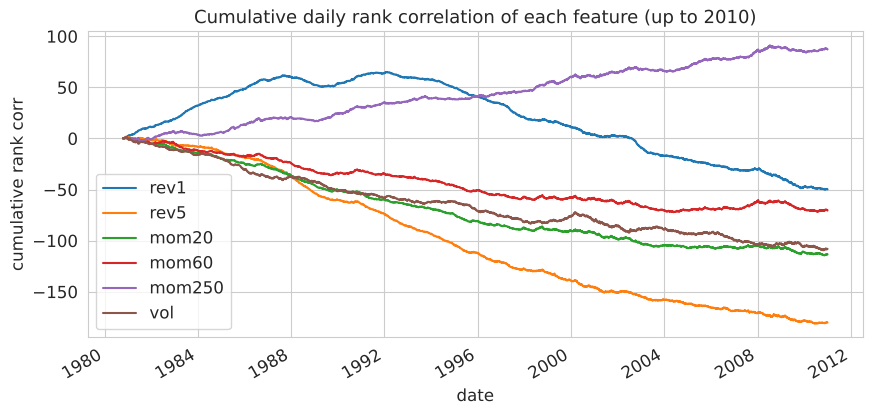

In [38]:
# daily rank correlation (Spearman) of each feature with tomorrow's return
d = panel.dropna()
ic = pd.DataFrame({f: d.groupby(level=0).apply(lambda g: g[f].corr(g["y"], method="spearman")) for f in FEATS})
print(pd.DataFrame({"1981-2000": ic[:"2000"].mean(), "2001-2010 (val)": ic["2001":"2010"].mean()}).round(4))

(ic[:"2010"].cumsum()).plot(figsize=(10, 4.5), title="Cumulative daily rank correlation of each feature (up to 2010)")
plt.ylabel("cumulative rank corr"); plt.show()

All signals are weak (|mean rank corr| ≈ 0.01–0.03). `rev1` changes sign around 1992, which is why we retrain on a rolling window.

### 3(c) Evaluation metrics
Predictions are demeaned each day and scaled so that Σ|r̂| = 1. Sharpe ratio: Eq. 4. PnL: Eq. 6. Holding period: Eq. 7.

In [39]:
real_next = radj.shift(-1).where(member)      # actual (unclipped) vol-adjusted return of tomorrow
market_next = ret.shift(-1)[member].mean(axis=1)   # equal-weighted long-only portfolio

def to_weights(p):
    p = p.sub(p.mean(axis=1), axis=0)           # market neutral
    return p.div(p.abs().sum(axis=1), axis=0)   # unit gross exposure

def evaluate(w, start=None, end=None):
    w = w.loc[start:end]
    rn = real_next.reindex_like(w)
    pnl = (w * rn).sum(axis=1, min_count=1).dropna()
    rank_ic = w.corrwith(rn, axis=1, method="spearman").dropna()
    hold = (w.abs().mean() / w.diff().abs().mean()).replace(np.inf, np.nan).mean()   # Eq. 7
    stats = {"Sharpe": pnl.mean() / pnl.std() * np.sqrt(252),
             "mean rank corr": rank_ic.mean(),
             "holding period": hold,
             "market corr": pnl.corr(market_next.reindex(pnl.index)),
             "min stocks/day": int(w.notna().sum(axis=1).min())}
    return stats, pnl, rank_ic

### 3(d) Rolling training and tuning (validation 2001–2010)

In [40]:
def rolling_predict(make_model, test_years, window=10, n_sub=None, data=panel, feats=FEATS):
    yrs = data.index.get_level_values(0).year
    out, models = [], {}
    for Y in test_years:
        tr = data[(yrs >= Y - window) & (yrs < Y)].dropna(subset=["y"])
        tr = tr[tr.index.get_level_values(0) < tr.index.get_level_values(0).max()]   # 1-day gap
        if n_sub and len(tr) > n_sub:            # subsample to keep RF / MLP fast
            tr = tr.sample(n_sub, random_state=42)
        te = data[yrs == Y]
        models[Y] = make_model().fit(tr[feats].values, tr["y"].values)
        out.append(pd.Series(models[Y].predict(te[feats].values), index=te.index))
    return to_weights(pd.concat(out).unstack()), models

VAL, TEST = range(2001, 2011), range(2011, 2014)

In [41]:
# Lasso: penalty alpha and training window length
lasso_res = {}
for window in [5, 10, 20]:
    for alpha in [1e-4, 1e-3, 3e-3, 1e-2]:
        w, _ = rolling_predict(lambda: Lasso(alpha=alpha), VAL, window=window)
        lasso_res[(window, alpha)] = evaluate(w)[0]
lasso_res = pd.DataFrame(lasso_res).T.rename_axis(["window", "alpha"])
lasso_res.round(3)

Sharpe  mean rank corr  holding period  market corr  \
window alpha                                                         
5      0.0001   1.067           0.016           1.425        0.158   
       0.0010   1.029           0.016           1.416        0.161   
       0.0030   0.944           0.014           1.416        0.162   
       0.0100   0.149           0.008         862.373        0.111   
10     0.0001   1.513           0.021           1.381        0.199   
       0.0010   1.498           0.021           1.370        0.206   
       0.0030   1.451           0.020           1.331        0.209   
       0.0100   1.151           0.015           1.390        0.186   
20     0.0001   1.271           0.014           1.755        0.197   
       0.0010   1.278           0.014           1.748        0.198   
       0.0030   1.298           0.015           1.706        0.199   
       0.0100   1.222           0.014           1.615        0.187   

               min stocks/day  
window alpha                   
5      0.0001           492.0  
       0.0010           492.0  
       0.0030           492.0  
       0.0100             0.0  
10     0.0001           492.0  
       0.0010           492.0  
       0.0030           492.0  
       0.0100           492.0  
20     0.0001           492.0  
       0.0010           492.0  
       0.0030           492.0  
       0.0100           492.0

In [42]:
best_window, best_alpha = lasso_res["Sharpe"].idxmax()
w_val_lasso, lasso_models = rolling_predict(lambda: Lasso(alpha=best_alpha), VAL, window=best_window)
print("Best Lasso: window =", best_window, " alpha =", best_alpha)
# coefficients learned each year
pd.DataFrame({Y: m.coef_ for Y, m in lasso_models.items()}, index=FEATS).T.round(4)

Best Lasso: window = 10  alpha = 0.0001


,rev1,rev5,mom20,mom60,mom250,vol
2001,-0.0038,-0.0237,0.0041,-0.0092,0.0089,-0.0089
2002,-0.0055,-0.0204,0.0037,-0.0105,0.0078,-0.0081
2003,-0.0087,-0.0152,0.0016,-0.0107,0.0086,-0.0079
2004,-0.0117,-0.0128,0.0015,-0.0107,0.0071,-0.0076
2005,-0.0103,-0.0108,0.0013,-0.0108,0.0079,-0.0091
2006,-0.0098,-0.0103,0.0033,-0.0109,0.0092,-0.0054
2007,-0.0094,-0.0086,0.0031,-0.0097,0.0080,-0.0069
2008,-0.0040,-0.0098,0.0031,-0.0082,0.0083,-0.0057
2009,-0.0050,-0.0094,0.0016,-0.0064,0.0052,-0.0052
2010,-0.0060,-0.0063,0.0002,-0.0079,0.0020,-0.0087


Best Lasso: 10-year window, α = 1e-4. Larger α removes weak features and lowers the Sharpe ratio. The row with window = 5 and α = 0.01 is degenerate: in 2009 and 2010 Lasso sets all six coefficients to exactly 0, so every stock gets the same prediction, the demeaned prediction is 0 for all stocks and the weights become NaN (0/0). That is why it shows 0 stocks/day and a meaningless holding period (862 days); this setting is excluded.

In [43]:
# RandomForest and MLP: small grids, trained on 200k sampled rows from the same 10-year window
nonlin_res, nonlin_w = {}, {}
rf_grid = [(4, 500), (8, 200), (12, 100)]      # (max_depth, min_samples_leaf)
for depth, leaf in rf_grid:
    w, _ = rolling_predict(lambda: RandomForestRegressor(n_estimators=50, max_depth=depth, min_samples_leaf=leaf,
                                                         max_features=0.5, n_jobs=-1, random_state=42),
                           VAL, window=best_window, n_sub=200_000)
    nonlin_res[f"RF depth={depth}, leaf={leaf}"], nonlin_w[("RF", depth)] = evaluate(w)[0], w

for hidden in [(8,), (32,), (32, 16)]:
    w, _ = rolling_predict(lambda: MLPRegressor(hidden_layer_sizes=hidden, alpha=1e-3, max_iter=30,
                                                early_stopping=True, random_state=42),
                           VAL, window=best_window, n_sub=200_000)
    nonlin_res[f"MLP hidden={hidden}"], nonlin_w[("MLP", hidden)] = evaluate(w)[0], w

nonlin_res = pd.DataFrame(nonlin_res).T
nonlin_res.round(3)

,Sharpe,mean rank corr,holding period,market corr,min stocks/day
"RF depth=4, leaf=500",1.996,0.021,1.199,0.181,492.0
"RF depth=8, leaf=200",2.678,0.022,1.049,0.197,492.0
"RF depth=12, leaf=100",2.921,0.020,0.950,0.195,492.0
"MLP hidden=(8,)",1.522,0.017,1.221,0.177,492.0
"MLP hidden=(32,)",2.428,0.018,1.130,0.200,492.0
"MLP hidden=(32, 16)",2.421,0.018,1.065,0.121,492.0


Chosen settings: RandomForest depth 8, leaf 200; MLP hidden = (32,). For the RandomForest we do not take depth 12 even though it has the highest validation Sharpe (2.92 vs 2.68): its holding period drops below 1 day and the deeper trees are more likely to overfit the noise, so we prefer the shallower model. Both beat Lasso on validation Sharpe, but they hold positions for only ~1 day.

### 3(e) Smoothing the predictions
Each stock's prediction is smoothed with a past-only EWMA (half-life h).

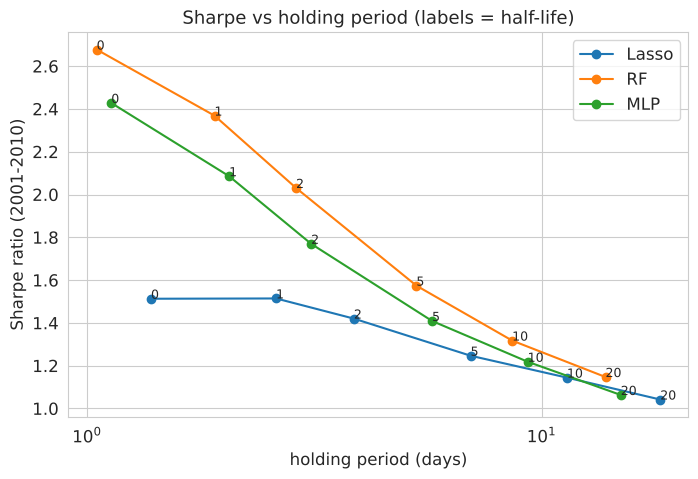

Sharpe  holding period  mean rank corr
model half-life                                        
Lasso 0           1.513           1.381           0.021
      1           1.514           2.603           0.019
      2           1.420           3.861           0.017
      5           1.247           6.973           0.014
      10          1.144          11.362           0.012
      20          1.042          18.225           0.011
RF    0           2.678           1.049           0.022
      1           2.369           1.905           0.019
      2           2.031           2.880           0.016
      5           1.574           5.299           0.013
      10          1.317           8.607           0.011
      20          1.147          13.811           0.009
MLP   0           2.428           1.130           0.018
      1           2.086           2.052           0.016
      2           1.770           3.109           0.013
      5           1.409           5.737           0.010
      10          1.218           9.311           0.008
      20          1.063          14.919           0.007

In [44]:
best_mlp = max([k for k in nonlin_w if k[0] == "MLP"], key=lambda k: nonlin_res.loc[f"MLP hidden={k[1]}", "Sharpe"])
val_preds = {"Lasso": w_val_lasso, "RF": nonlin_w[("RF", 8)], "MLP": nonlin_w[best_mlp]}

def smooth(w, halflife):
    if halflife == 0:
        return w
    return to_weights(w.ewm(halflife=halflife, ignore_na=True).mean().where(w.notna()))

smooth_res = {(name, h): evaluate(smooth(w, h))[0] for name, w in val_preds.items() for h in [0, 1, 2, 5, 10, 20]}
smooth_res = pd.DataFrame(smooth_res).T.rename_axis(["model", "half-life"])

plt.figure(figsize=(8, 5))
for name in val_preds:
    r = smooth_res.loc[name]
    plt.plot(r["holding period"], r["Sharpe"], "o-", label=name)
    for h, row in r.iterrows():
        plt.annotate(str(h), (row["holding period"], row["Sharpe"]), fontsize=9)
plt.xscale("log"); plt.xlabel("holding period (days)"); plt.ylabel("Sharpe ratio (2001-2010)")
plt.title("Sharpe vs holding period (labels = half-life)"); plt.legend(); plt.show()
smooth_res[["Sharpe", "holding period", "mean rank corr"]].round(3)

Smoothing lengthens the holding period but lowers the Sharpe ratio. We pick h = 2 (validation holding period ≈ 2.9–3.9 days).

### 3(f) Final test (2011–2013)

In [45]:
w_test = {"Lasso": rolling_predict(lambda: Lasso(alpha=best_alpha), TEST, window=best_window)[0],
          "RF": rolling_predict(lambda: RandomForestRegressor(n_estimators=50, max_depth=8, min_samples_leaf=200,
                                                              max_features=0.5, n_jobs=-1, random_state=42),
                                TEST, window=best_window, n_sub=200_000)[0],
          "MLP": rolling_predict(lambda: MLPRegressor(hidden_layer_sizes=best_mlp[1], alpha=1e-3, max_iter=30,
                                                      early_stopping=True, random_state=42),
                                 TEST, window=best_window, n_sub=200_000)[0]}

HL = 2
test_res, test_pnl, test_ic = {}, {}, {}
for name, w in w_test.items():
    for h in [0, HL]:
        label = f"{name} (h={h})"
        test_res[label], test_pnl[label], test_ic[label] = evaluate(smooth(w, h))
pd.DataFrame(test_res).T.round(3)

,Sharpe,mean rank corr,holding period,market corr,min stocks/day
Lasso (h=0),1.901,0.023,1.314,0.315,494.0
Lasso (h=2),1.956,0.022,4.256,0.315,494.0
RF (h=0),4.031,0.020,0.904,0.349,494.0
RF (h=2),2.885,0.018,2.293,0.417,494.0
MLP (h=0),2.469,0.016,1.058,0.165,494.0
MLP (h=2),1.711,0.016,2.943,0.187,494.0


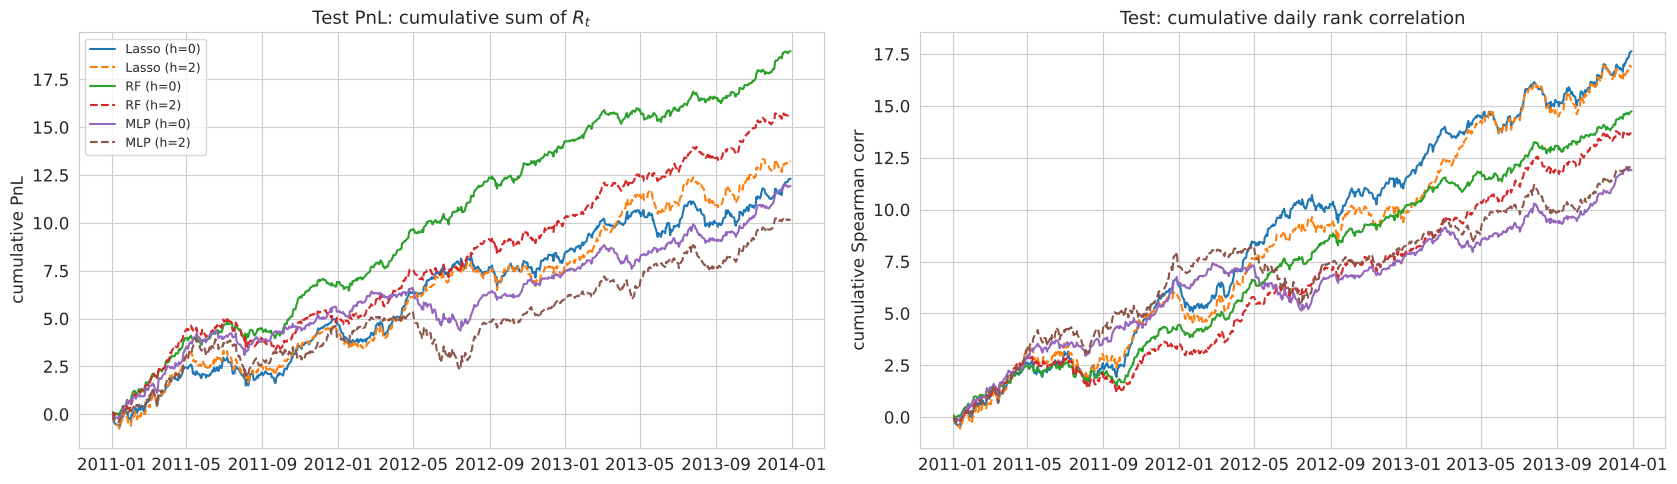

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for label in test_pnl:
    ls = "-" if label.endswith("h=0)") else "--"
    axes[0].plot(test_pnl[label].cumsum(), ls, label=label)
    axes[1].plot(test_ic[label].cumsum(), ls, label=label)
axes[0].set_title("Test PnL: cumulative sum of $R_t$"); axes[0].set_ylabel("cumulative PnL")
axes[1].set_title("Test: cumulative daily rank correlation"); axes[1].set_ylabel("cumulative Spearman corr")
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

,2001-2005,2006-2010,2011-2013 (test),2001-2013 (all)
Lasso (h=0),1.83,1.18,1.90,1.59
Lasso (h=2),1.83,0.98,1.98,1.54
RF (h=0),2.89,2.45,4.03,2.90
RF (h=2),2.44,1.57,2.90,2.20
MLP (h=0),2.31,2.66,2.47,2.43
MLP (h=2),1.88,1.67,1.77,1.77


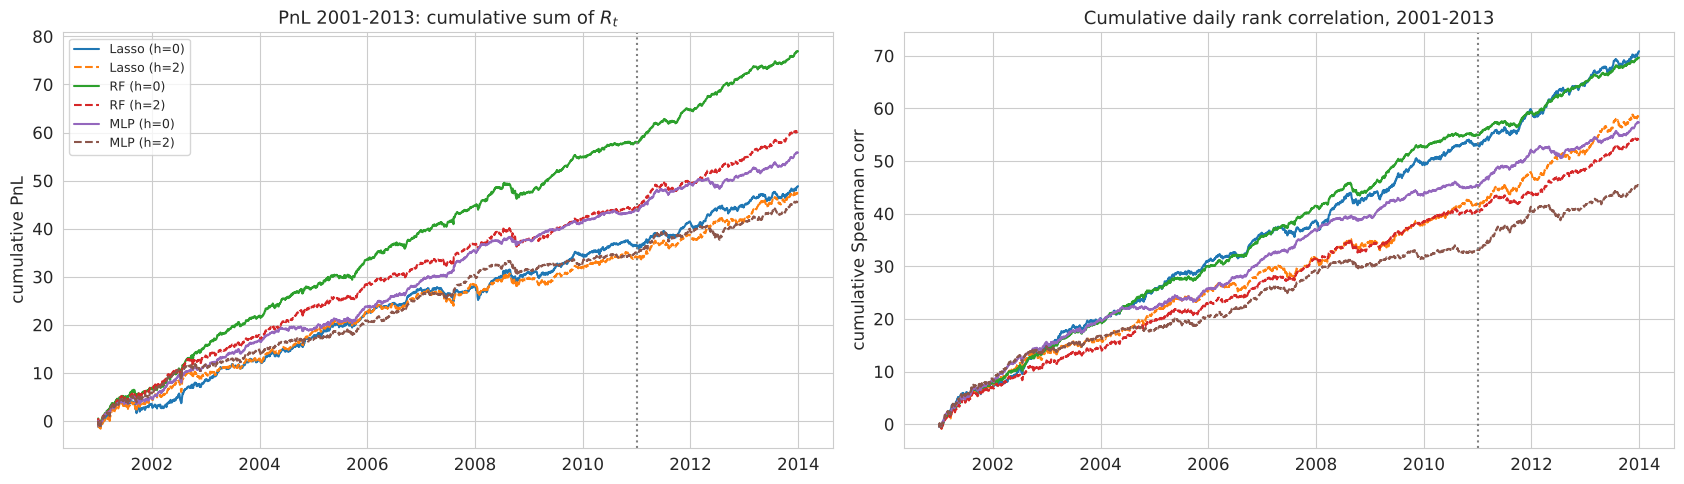

date,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Lasso (h=0),1.06,1.95,2.22,2.39,2.24,2.63,0.18,0.87,1.90,0.99,2.23,1.66,1.82
Lasso (h=2),1.50,1.89,1.48,2.73,1.90,2.07,0.65,0.50,1.19,1.02,2.06,1.47,2.43
RF (h=0),2.29,3.55,3.44,2.85,2.83,3.16,2.43,1.07,5.09,1.98,4.15,4.64,3.24
RF (h=2),2.40,2.51,2.34,2.85,2.31,2.39,1.81,0.43,2.93,1.40,2.68,2.73,3.41
MLP (h=0),1.77,3.22,2.94,1.58,2.40,3.56,3.83,1.26,3.02,2.04,3.26,1.21,3.08
MLP (h=2),2.01,2.49,1.59,1.34,1.88,3.43,2.24,0.66,1.01,1.39,1.97,0.99,2.51


In [47]:
# Sharpe over sub-periods and over the whole 2001-2013 period (validation models + test models)
windows = {"2001-2005": ("2001", "2005"), "2006-2010": ("2006", "2010"),
           "2011-2013 (test)": ("2011", "2013"), "2001-2013 (all)": ("2001", "2013")}
all_w = {name: pd.concat([val_preds[name], w_test[name]]) for name in val_preds}
display(pd.DataFrame({f"{name} (h={h})": {win: evaluate(smooth(w, h), a, b)[0]["Sharpe"] for win, (a, b) in windows.items()}
                      for name, w in all_w.items() for h in [0, HL]}).T.round(2))

# PnL and rank correlation for the whole period, so we can see if the performance is steady over time
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
yearly = {}
for name, w in all_w.items():
    for h in [0, HL]:
        _, pnl, ic = evaluate(smooth(w, h))
        ls = "-" if h == 0 else "--"
        axes[0].plot(pnl.cumsum(), ls, label=f"{name} (h={h})")
        axes[1].plot(ic.cumsum(), ls, label=f"{name} (h={h})")
        yearly[f"{name} (h={h})"] = pnl.groupby(pnl.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(252))
for ax in axes:
    ax.axvline(pd.Timestamp("2011-01-01"), color="gray", ls=":")   # test set starts here
axes[0].set_title("PnL 2001-2013: cumulative sum of $R_t$"); axes[0].set_ylabel("cumulative PnL")
axes[1].set_title("Cumulative daily rank correlation, 2001-2013"); axes[1].set_ylabel("cumulative Spearman corr")
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

# Sharpe of each year, to check for bad years
pd.DataFrame(yearly).T.round(2)


- All models have a positive test Sharpe ratio. RF is best (SR 4.0, or 2.9 with h = 2). Smoothed Lasso reaches SR ≈ 2.0 with a holding period of ≈ 4.3 days.
- Every year from 2001 to 2013 is positive for every model. The weakest years are 2007–2008.
- Market correlation is ≈ 0.17–0.42, because the low-volatility tilt makes the dollar exposure net long. Transaction costs are not included.

### 3(g) Adding the Psychsignal sentiment signals
Lasso with vs without net sentiment and activity (7-day averages). Trained from 2009-07, tested on 2011–2013.

In [48]:
# map sentiment to the return columns (first column for duplicated permnos) and to trading days
cols = [c for c in ret.columns if c in bull.columns]
net = (bull - bear).rolling("7D").mean()
activity = (bull + bear).rolling("7D").mean()
sent = {"net_sent": net, "activity": activity}
sent = {k: v.reindex(columns=cols).reindex(ret.index).reindex(columns=ret.columns) for k, v in sent.items()}

print("Stocks with sentiment per day (members):")
print(sent["net_sent"].where(member).notna().sum(axis=1)["2009-07":"2013"].resample("YE").mean().round(0))

panel_s = panel.loc["2009-07":"2013"].copy()
for k, v in sent.items():
    panel_s[k] = cs_zscore(v).stack().reindex(panel_s.index).fillna(0)   # no messages -> neutral
FEATS_S = FEATS + list(sent)

# rank correlation of the sentiment features with tomorrow's return (2009-07 to 2010, training period)
d = panel_s.loc[:"2010"].dropna()
print(pd.Series({f: d.groupby(level=0).apply(lambda g: g[f].corr(g["y"], method="spearman")).mean()
                 for f in sent}).round(4))

Stocks with sentiment per day (members):
date
2009-12-31     57.0
2010-12-31    120.0
2011-12-31    174.0
2012-12-31    206.0
2013-12-31    233.0
Freq: YE-DEC, dtype: float64


net_sent   -0.0048
activity    0.0044
dtype: float64


In [49]:
sent_res = {}
for name, feats in [("Lasso, returns only", FEATS), ("Lasso, returns + sentiment", FEATS_S)]:
    w, models = rolling_predict(lambda: Lasso(alpha=best_alpha), TEST, window=3, data=panel_s, feats=feats)  # up to 3 years, starting 2009-07
    for h in [0, HL]:
        sent_res[f"{name} (h={h})"] = evaluate(smooth(w, h))[0]
    if feats == FEATS_S:   # keep the sentiment model's coefficients to inspect them
        sent_coef = pd.DataFrame({Y: m.coef_ for Y, m in models.items()}, index=feats).T
display(pd.DataFrame(sent_res).T.round(3))
sent_coef.round(4)

,Sharpe,mean rank corr,holding period,market corr,min stocks/day
"Lasso, returns only (h=0)",1.783,0.020,1.387,0.262,494.0
"Lasso, returns only (h=2)",1.517,0.016,5.119,0.259,494.0
"Lasso, returns + sentiment (h=0)",1.917,0.021,1.394,0.261,494.0
"Lasso, returns + sentiment (h=2)",1.608,0.017,4.897,0.254,494.0


,rev1,rev5,mom20,mom60,mom250,vol,net_sent,activity
2011,-0.0066,0.0013,-0.0023,-0.0088,-0.0007,-0.0061,-0.0029,0.0059
2012,-0.0069,-0.0015,-0.0020,-0.0057,0.0012,-0.0109,-0.0005,0.0066
2013,-0.0054,-0.0000,-0.0020,-0.0028,0.0017,-0.0104,-0.0011,0.0059


Sentiment adds only a small, non-significant gain (test SR 1.78 → 1.92 unsmoothed, 1.52 → 1.61 with h = 2).